# End-to-End Supervised Machine Learning Pipeline for Rain Prediction

## Project Overview
This repository contains a production-ready supervised machine learning pipeline designed to predict next-day precipitation (`RainTomorrow`) from historical meteorological observations.


- **Multicollinearity & Redundancy:** Compressing highly correlated temporal variables (morning vs. afternoon measurements) into aggregate climatic indicators.
- **Seasonality Extraction:** Decomposing timestamp data to capture seasonal weather dynamics.
- **Data Quality & Imbalance:** Systemic handling of missing values (imputation strategies) and class imbalance across binary precipitation targets.
- **Model Benchmarking:** Comparative evaluation of classical estimators (Logistic Regression, Random Forest, Support Vector Machines, Gradient Boosting) optimized for multiple metrics.

# IMPORTS

In [ ]:
#IMPORTS
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest,chi2
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score
from typing import Dict, List, Any, Tuple
from sklearn.base import BaseEstimator
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

## Dataset  Context
The analysis is conducted on the benchmark **Rain in Australia** dataset (sourced via Kaggle / Australian Commonwealth Bureau of Meteorology).

The dataset contains daily weather observations from numerous Australian meteorological stations over an extended period. The target variable is `RainTomorrow` (binary: Yes/No), indicating whether it is goining to be rain on the following day. Features include temperature, atmospheric pressure gradients, humidity percentages, wind metrics, and rainfall measurements.

In [ ]:
# Loading the data
def load_data(url:str)-> pd.DataFrame:
    return pd.read_csv(url)

In [ ]:
from google.colab import drive
drive.mount("/content/gdrive", force_remount=True)

train_data_url="/content/gdrive/MyDrive/Colab Notebooks/train-val.csv"
train_data= load_data(train_data_url)

Mounted at /content/gdrive


In [ ]:
train_data

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2009-03-22,Albury,14.6,30.0,0.0,NaN,NaN,NE,37.0,E,...,56.0,30.0,1014.8,1012.7,3.0,1.0,18.1,29.0,No,No
1,2009-04-15,Albury,10.7,21.9,0.0,NaN,NaN,W,63.0,NW,...,44.0,27.0,1008.2,1009.8,2.0,NaN,20.5,18.9,No,No
2,2009-04-21,Albury,5.7,21.4,0.0,NaN,NaN,ESE,17.0,ENE,...,68.0,39.0,1025.2,1020.9,NaN,NaN,12.2,20.9,No,No
3,2009-04-24,Albury,10.6,16.2,0.0,NaN,NaN,WNW,39.0,ESE,...,74.0,86.0,1008.9,1002.4,8.0,8.0,14.9,15.1,No,Yes
4,2009-05-19,Albury,3.7,19.1,0.0,NaN,NaN,SSE,19.0,NaN,...,87.0,51.0,1023.6,1019.9,NaN,NaN,7.4,18.9,No,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,2017-04-30,Uluru,12.7,21.0,0.0,NaN,NaN,ENE,26.0,E,...,50.0,34.0,1019.6,1016.1,7.0,NaN,15.3,20.5,No,No
9996,2017-05-07,Uluru,10.8,27.0,0.0,NaN,NaN,ENE,44.0,ESE,...,31.0,17.0,1026.4,1022.5,NaN,NaN,16.8,26.3,No,No
9997,2017-05-11,Uluru,4.1,24.7,0.0,NaN,NaN,E,26.0,ESE,...,33.0,17.0,1022.1,1017.2,NaN,NaN,13.4,23.7,No,No
9998,2017-06-09,Uluru,3.4,19.8,0.0,NaN,NaN,E,43.0,ESE,...,54.0,23.0,1031.8,1027.7,NaN,NaN,8.7,18.9,No,No


#Exploratory Data Analysis (EDA)


In [ ]:
#DATA INFO
print(train_data.info)


<bound method DataFrame.info of             Date Location  MinTemp  MaxTemp  Rainfall  Evaporation  Sunshine  \
0     2009-03-22   Albury     14.6     30.0       0.0          NaN       NaN   
1     2009-04-15   Albury     10.7     21.9       0.0          NaN       NaN   
2     2009-04-21   Albury      5.7     21.4       0.0          NaN       NaN   
3     2009-04-24   Albury     10.6     16.2       0.0          NaN       NaN   
4     2009-05-19   Albury      3.7     19.1       0.0          NaN       NaN   
...          ...      ...      ...      ...       ...          ...       ...   
9995  2017-04-30    Uluru     12.7     21.0       0.0          NaN       NaN   
9996  2017-05-07    Uluru     10.8     27.0       0.0          NaN       NaN   
9997  2017-05-11    Uluru      4.1     24.7       0.0          NaN       NaN   
9998  2017-06-09    Uluru      3.4     19.8       0.0          NaN       NaN   
9999  2017-06-17    Uluru      6.4     23.4       0.0          NaN       NaN   

     Wi

In [ ]:
#DATA TYPES
print(train_data.dtypes)

Date              object
Location          object
MinTemp          float64
MaxTemp          float64
Rainfall         float64
Evaporation      float64
Sunshine         float64
WindGustDir       object
WindGustSpeed    float64
WindDir9am        object
WindDir3pm        object
WindSpeed9am     float64
WindSpeed3pm     float64
Humidity9am      float64
Humidity3pm      float64
Pressure9am      float64
Pressure3pm      float64
Cloud9am         float64
Cloud3pm         float64
Temp9am          float64
Temp3pm          float64
RainToday         object
RainTomorrow      object
dtype: object


In [ ]:
#LABEL NAMES
def get_label_names(data_df:pd.DataFrame)->List[str]:
    return data_df.columns.tolist()

In [ ]:
label_names=get_label_names(train_data)
print(label_names)

['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'RainTomorrow']


In [ ]:
#Unique values for a category
train_data["RainTomorrow"].unique()
print(train_data["RainTomorrow"].unique())
print(len(train_data["RainTomorrow"].unique()))

['No' 'Yes' nan]
3


In [ ]:
 #Number of samples in each category
train_data["RainTomorrow"].value_counts(dropna=False)

,count
RainTomorrow,
No,7483
Yes,2317
NaN,200


                MinTemp   MaxTemp  Rainfall  Evaporation  Sunshine  \
MinTemp        1.000000  0.709757  0.095608     0.458028  0.041574   
MaxTemp        0.709757  1.000000 -0.102101     0.575044  0.462081   
Rainfall       0.095608 -0.102101  1.000000    -0.078567 -0.236318   
Evaporation    0.458028  0.575044 -0.078567     1.000000  0.339121   
Sunshine       0.041574  0.462081 -0.236318     0.339121  1.000000   
WindGustSpeed  0.150573  0.000538  0.171510     0.171596 -0.098688   
WindSpeed9am   0.176429 -0.009186  0.114725     0.195804 -0.033354   
WindSpeed3pm   0.173667  0.048909  0.079085     0.153693  0.025456   
Humidity9am   -0.225683 -0.487721  0.217840    -0.504436 -0.457572   
Humidity3pm    0.026422 -0.505189  0.255563    -0.369323 -0.624995   
Pressure9am   -0.359337 -0.212820 -0.178036    -0.201344  0.121638   
Pressure3pm   -0.372178 -0.316488 -0.119917    -0.233252  0.055903   
Cloud9am       0.080615 -0.294401  0.205555    -0.164623 -0.690633   
Cloud3pm       0.022

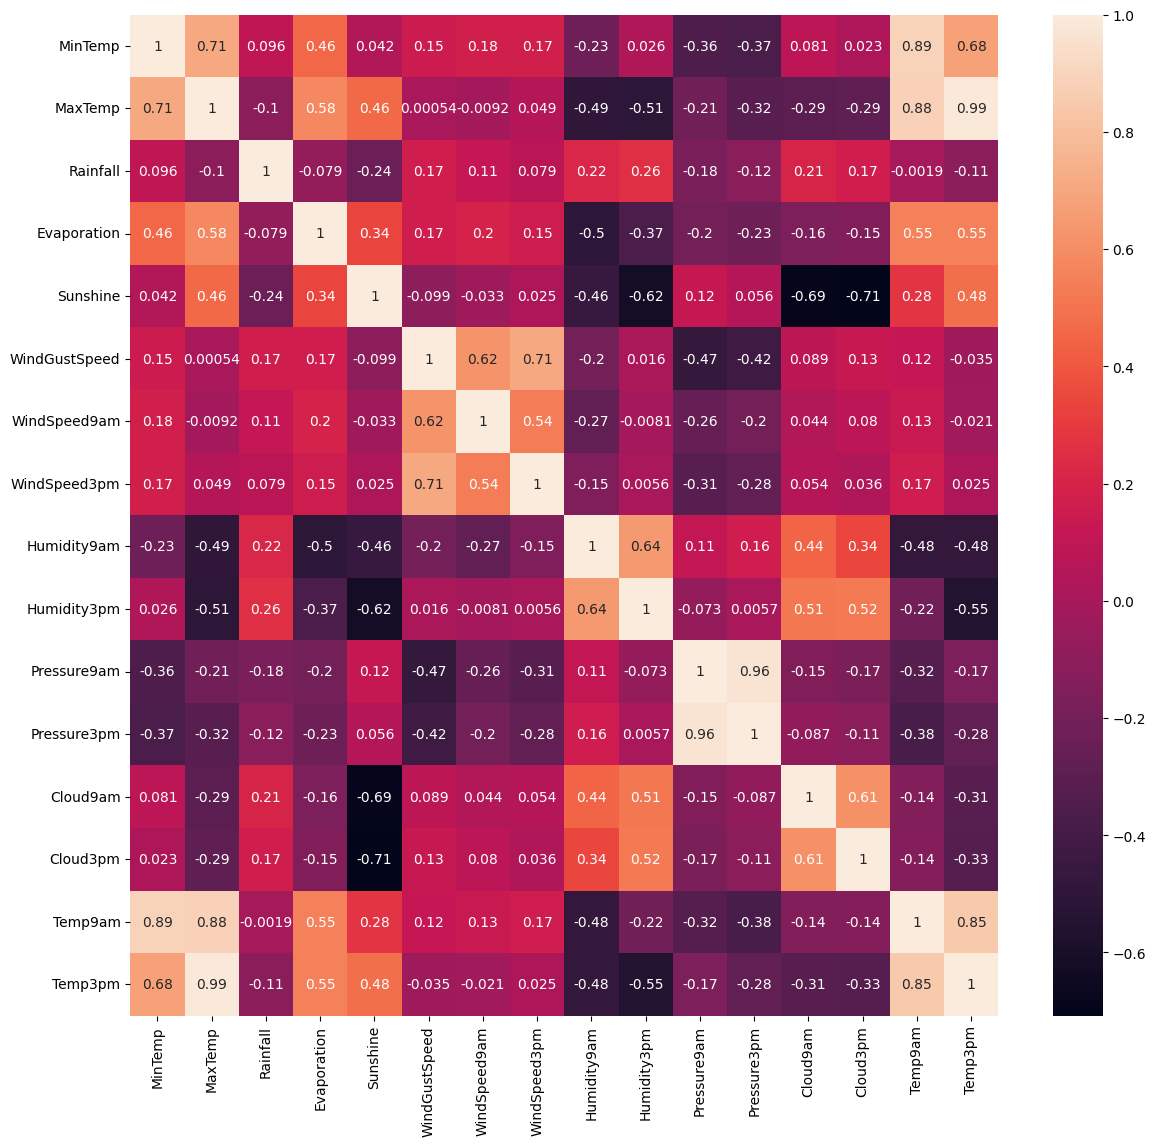

In [ ]:
# Data correlation and heatmap
numerical_data = train_data.select_dtypes(include='number')# only the numerical data for the correlation
correlation=numerical_data.corr()
print(correlation)

plt.figure(figsize=(14,13))
sns.heatmap(correlation,annot=True)#annot=TRUE, in order for the correlation number between the features to show in each cell of the heatmap
plt.show()

# Data pre-processing





Not all data features will be used. Some will be dropped, some will be merged to create new features, and others will simply be used in a different, more manageable format. More specifically, the 'Date' feature will be dropped. However, it is quite an important feature for predicting rain tomorrow, so in its place I will keep the integer month_number. Also, for the features ("MaxTemp", "MinTemp"), ("Pressure9am", "Pressure3pm"), ("WindSpeed9am", "WindSpeed3pm"), ("Temp9am", "Temp3pm"), ("Humidity9am", "Humidity3pm"), and ("Cloud9am", "Cloud3pm"), I will create their respective averages with the ultimate goal of simplifying the dataset. Finally, features such as 'Evaporation' and 'Sunshine' will be dropped due to their large number of missing values. This specific drop will be done to avoid errors and inaccuracies during the missing value imputation process.

##  NEW FEATURES AND CHANGES

In [ ]:
train_data = load_data(train_data_url)

Through the correlation analysis, a very strong correlation between several pairs of features that measure almost the same thing can be easily found. Two strongly correlated columns provide redundant information to the model which is completely unnecessary. This can create problems for the classifier and make the results unstable. The solution to this problem is to combine two almost identical columns (e.g., Pressure9am and Pressure3pm) into one (Ps_mean). This new column represents the core information without the noise of the two separate measurements. Columns with a correlation above 0.70 have been considered as highly correlated. Such columns are ("MaxTemp", "MinTemp"), ("Pressure9am", "Pressure3pm"), ("WindSpeed9am", "WindSpeed3pm"), ("Temp9am", "Temp3pm"), ("Humidity9am", "Humidity3pm"), and ("Cloud9am", "Cloud3pm"). The choice of the mean as the new column is made purely for practical and computational reasons.

In [ ]:
def get_month_number_column(data_df:pd.DataFrame)->pd.DataFrame: #The new  feature 'month_number' by ''changing'' the  feature 'date'
    data_df['Date'] = pd.to_datetime(data_df['Date'], format='mixed')
    data_df["Month_number"]=data_df["Date"].dt.month
    return data_df

def create_mean_features(data_df:pd.DataFrame, cols:Dict[str, Tuple[str, str]])->pd.DataFrame:# the new 'mean' features

    for new_column, (old_col1, old_col2) in cols.items():
        data_df[new_column]=(data_df[old_col1]+data_df[old_col2])/2
    return data_df

In [ ]:
columns_config = {"Mean_Temp": ("MaxTemp", "MinTemp"),
                  "Ps_mean":("Pressure9am","Pressure3pm"),
                  "Ws_mean":("WindSpeed9am","WindSpeed3pm"),
                  "Temp_mean":("Temp9am","Temp3pm"),
                  "Humid_mean":("Humidity9am","Humidity3pm"),
                  "Cloud_mean":("Cloud9am","Cloud3pm")
                  }
train_data = get_month_number_column(train_data)
train_data = create_mean_features(train_data, columns_config)
print(train_data)

           Date Location  MinTemp  MaxTemp  Rainfall  Evaporation  Sunshine  \
0    2009-03-22   Albury     14.6     30.0       0.0          NaN       NaN   
1    2009-04-15   Albury     10.7     21.9       0.0          NaN       NaN   
2    2009-04-21   Albury      5.7     21.4       0.0          NaN       NaN   
3    2009-04-24   Albury     10.6     16.2       0.0          NaN       NaN   
4    2009-05-19   Albury      3.7     19.1       0.0          NaN       NaN   
...         ...      ...      ...      ...       ...          ...       ...   
9995 2017-04-30    Uluru     12.7     21.0       0.0          NaN       NaN   
9996 2017-05-07    Uluru     10.8     27.0       0.0          NaN       NaN   
9997 2017-05-11    Uluru      4.1     24.7       0.0          NaN       NaN   
9998 2017-06-09    Uluru      3.4     19.8       0.0          NaN       NaN   
9999 2017-06-17    Uluru      6.4     23.4       0.0          NaN       NaN   

     WindGustDir  WindGustSpeed WindDir9am  ... Tem

In [ ]:
train_data

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Temp3pm,RainToday,RainTomorrow,Month_number,Mean_Temp,Ps_mean,Ws_mean,Temp_mean,Humid_mean,Cloud_mean
0,2009-03-22,Albury,14.6,30.0,0.0,NaN,NaN,NE,37.0,E,...,29.0,No,No,3,22.30,1013.75,11.5,23.55,43.0,2.0
1,2009-04-15,Albury,10.7,21.9,0.0,NaN,NaN,W,63.0,NW,...,18.9,No,No,4,16.30,1009.00,28.5,19.70,35.5,NaN
2,2009-04-21,Albury,5.7,21.4,0.0,NaN,NaN,ESE,17.0,ENE,...,20.9,No,No,4,13.55,1023.05,6.5,16.55,53.5,NaN
3,2009-04-24,Albury,10.6,16.2,0.0,NaN,NaN,WNW,39.0,ESE,...,15.1,No,Yes,4,13.40,1005.65,5.5,15.00,80.0,8.0
4,2009-05-19,Albury,3.7,19.1,0.0,NaN,NaN,SSE,19.0,NaN,...,18.9,No,No,5,11.40,1021.75,5.5,13.15,69.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,2017-04-30,Uluru,12.7,21.0,0.0,NaN,NaN,ENE,26.0,E,...,20.5,No,No,4,16.85,1017.85,12.0,17.90,42.0,NaN
9996,2017-05-07,Uluru,10.8,27.0,0.0,NaN,NaN,ENE,44.0,ESE,...,26.3,No,No,5,18.90,1024.45,20.5,21.55,24.0,NaN
9997,2017-05-11,Uluru,4.1,24.7,0.0,NaN,NaN,E,26.0,ESE,...,23.7,No,No,5,14.40,1019.65,10.0,18.55,25.0,NaN
9998,2017-06-09,Uluru,3.4,19.8,0.0,NaN,NaN,E,43.0,ESE,...,18.9,No,No,6,11.60,1029.75,21.5,13.80,38.5,NaN


In [ ]:
train_data.columns

Index(['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation',
       'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm',
       'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm',
       'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am',
       'Temp3pm', 'RainToday', 'RainTomorrow', 'Month_number', 'Mean_Temp',
       'Ps_mean', 'Ws_mean', 'Temp_mean', 'Humid_mean', 'Cloud_mean'],
      dtype='object')

In [ ]:
train_data

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Temp3pm,RainToday,RainTomorrow,Month_number,Mean_Temp,Ps_mean,Ws_mean,Temp_mean,Humid_mean,Cloud_mean
0,2009-03-22,Albury,14.6,30.0,0.0,NaN,NaN,NE,37.0,E,...,29.0,No,No,3,22.30,1013.75,11.5,23.55,43.0,2.0
1,2009-04-15,Albury,10.7,21.9,0.0,NaN,NaN,W,63.0,NW,...,18.9,No,No,4,16.30,1009.00,28.5,19.70,35.5,NaN
2,2009-04-21,Albury,5.7,21.4,0.0,NaN,NaN,ESE,17.0,ENE,...,20.9,No,No,4,13.55,1023.05,6.5,16.55,53.5,NaN
3,2009-04-24,Albury,10.6,16.2,0.0,NaN,NaN,WNW,39.0,ESE,...,15.1,No,Yes,4,13.40,1005.65,5.5,15.00,80.0,8.0
4,2009-05-19,Albury,3.7,19.1,0.0,NaN,NaN,SSE,19.0,NaN,...,18.9,No,No,5,11.40,1021.75,5.5,13.15,69.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,2017-04-30,Uluru,12.7,21.0,0.0,NaN,NaN,ENE,26.0,E,...,20.5,No,No,4,16.85,1017.85,12.0,17.90,42.0,NaN
9996,2017-05-07,Uluru,10.8,27.0,0.0,NaN,NaN,ENE,44.0,ESE,...,26.3,No,No,5,18.90,1024.45,20.5,21.55,24.0,NaN
9997,2017-05-11,Uluru,4.1,24.7,0.0,NaN,NaN,E,26.0,ESE,...,23.7,No,No,5,14.40,1019.65,10.0,18.55,25.0,NaN
9998,2017-06-09,Uluru,3.4,19.8,0.0,NaN,NaN,E,43.0,ESE,...,18.9,No,No,6,11.60,1029.75,21.5,13.80,38.5,NaN


## Handling missing Values

In [ ]:
def find_null_data(data_df:pd.DataFrame)->None: #counting the  missing values of each  feature
    data_df.isnull().sum()
    print(data_df.isnull().sum())
    return

In [ ]:
find_null_data(train_data)

Date                0
Location            0
MinTemp           101
MaxTemp            69
Rainfall          219
Evaporation      4337
Sunshine         4825
WindGustDir       748
WindGustSpeed     744
WindDir9am        795
WindDir3pm        312
WindSpeed9am      117
WindSpeed3pm      211
Humidity9am       189
Humidity3pm       311
Pressure9am      1027
Pressure3pm      1030
Cloud9am         3845
Cloud3pm         4050
Temp9am           125
Temp3pm           253
RainToday         219
RainTomorrow      200
Month_number        0
Mean_Temp         117
Ps_mean          1042
Ws_mean           251
Temp_mean         296
Humid_mean        365
Cloud_mean       4365
dtype: int64


In [ ]:
# missing values percentage of each  feature
def get_missing_percentage(dataframe: pd.DataFrame) -> pd.DataFrame:
    missing_counts = dataframe.isnull().sum()
    total_rows = len(dataframe)
    missing_percentage = (missing_counts / total_rows) * 100
    missing_percentage = missing_percentage.sort_values(ascending=False)
    return missing_percentage


In [ ]:
missing_values_percent = get_missing_percentage(train_data)
print("PERCENTAGE OF MISSING VALUES:\n\n", missing_values_percent)

PERCENTAGE OF MISSING VALUES:

 Sunshine         48.25
Cloud_mean       43.65
Evaporation      43.37
Cloud3pm         40.50
Cloud9am         38.45
Ps_mean          10.42
Pressure3pm      10.30
Pressure9am      10.27
WindDir9am        7.95
WindGustDir       7.48
WindGustSpeed     7.44
Humid_mean        3.65
WindDir3pm        3.12
Humidity3pm       3.11
Temp_mean         2.96
Temp3pm           2.53
Ws_mean           2.51
RainToday         2.19
Rainfall          2.19
WindSpeed3pm      2.11
RainTomorrow      2.00
Humidity9am       1.89
Temp9am           1.25
WindSpeed9am      1.17
Mean_Temp         1.17
MinTemp           1.01
MaxTemp           0.69
Date              0.00
Location          0.00
Month_number      0.00
dtype: float64


From missing_values_percent, we can draw very important conclusions for each feature. More specifically, I observe that several features had a very high percentage of missing values (some over 40%). More specifically, the features Sunshine (48.2%) and Evaporation (43.3%) were dropped from the dataset, as due to the large number of missing values, we would be led to many errors and inaccuracies during the imputation process. Any imputation to such an extent would introduce massive noise and bias into the model, distorting the results.

Another important problem that is created has to do with the new features created from the old ones. Specifically, the features Cloud3pm (40.5%) and Cloud9am (38.4%) also had high percentages of missing values. However, they were used to create the new feature of their average (which also had a fairly high percentage of missing values). Despite this, the choice was made to drop only Cloud3pm and Cloud9am in order to avoid multicollinearity, meaning the presence of redundant information that would confuse the model. To avoid this exact problem, all other features that helped in creating their respective averages were dropped, as mentioned above.



## Dropping features

In [ ]:
def drop_columns(data_df:pd.DataFrame, cols_to_drop:Tuple[str, str])->pd.DataFrame: # dropping features
    for c in cols_to_drop:
        data_df=data_df.drop(c,axis=1)
    return data_df

In [ ]:
cols_to_drop=["Date",'MaxTemp', "MinTemp","Pressure9am","Pressure3pm", "WindSpeed9am","WindSpeed3pm","Temp9am","Temp3pm","Humidity9am","Humidity3pm","Cloud9am","Cloud3pm",'Evaporation','Sunshine']
train_data=drop_columns(train_data,cols_to_drop)

## Missing Values replacement

For the replacement of missing values, SimpleImputer was used as the imputer for both numerical and categorical data. The difference was in the choice of strategy. For categorical data, it replaces missing values with the most frequent occurrence using strategy='most_frequent', while for numerical data, with the 'median' strategy, the replacement of missing values is done using the median. It is worth noting that other imputers such as KNNImputer were also tested, however, they produced somewhat worse results in subsequent experiments, which is why SimpleImputer was chosen.

In [ ]:
def replace_missing_vals(data_df:pd.DataFrame)->pd.DataFrame: #Replace the  missing values of the features by using Simpleimputer
    for c in data_df.columns:
        if data_df[c].isnull().sum() > 0:
            if data_df[c].dtype=="float64": #numerical type
                strategy = 'median'
            elif  data_df[c].dtype==object: #categorical type. This line includes 'elif' and not just 'else' because the feature  'month_number' has a different type. However 'mont_number' has no missing values and thus is not included as an extra case.
                strategy = 'most_frequent'
            c = [c]
            imputer=SimpleImputer(missing_values=np.nan,strategy=strategy)
            imputation_data = data_df[c].copy()
            imputer.fit(imputation_data)
            data_df[c] = imputer.transform(data_df[c])
    return data_df

In [ ]:
train_data=replace_missing_vals(train_data)

## Categorical values replacement

In [ ]:
def get_categorical_mapping(data_df:pd.DataFrame)->Dict[str, int]: #Dict  that maps each categorical value to the corresponding numerical one, in order to have a better data set management and scaling


     mapping = {}
     for c in data_df.columns:
         if data_df[c].dtype==object:
             unq_vals=data_df[c].unique().tolist()

             for index, value in enumerate(unq_vals):
                 if value not in mapping.keys():  # only the new categorical values
                     mapping[value]= index

     return mapping
def replace_categorical_values(data_df:pd.DataFrame)->pd.DataFrame: #Replace the categorical values with the numerical ones

     categorical_mapping = get_categorical_mapping(data_df)
     for c in data_df.columns:
         if data_df[c].dtype==object:
             data_df[c]=data_df[c].map(categorical_mapping)

     return data_df

In [ ]:
get_categorical_mapping(train_data)

{'Albury': 0,
 'BadgerysCreek': 1,
 'Cobar': 2,
 'CoffsHarbour': 3,
 'Moree': 4,
 'Newcastle': 5,
 'NorahHead': 6,
 'NorfolkIsland': 7,
 'Penrith': 8,
 'Richmond': 9,
 'Sydney': 10,
 'SydneyAirport': 11,
 'WaggaWagga': 12,
 'Williamtown': 13,
 'Wollongong': 14,
 'Canberra': 15,
 'Tuggeranong': 16,
 'MountGinini': 17,
 'Ballarat': 18,
 'Bendigo': 19,
 'Sale': 20,
 'MelbourneAirport': 21,
 'Melbourne': 22,
 'Mildura': 23,
 'Nhil': 24,
 'Portland': 25,
 'Watsonia': 26,
 'Dartmoor': 27,
 'Brisbane': 28,
 'Cairns': 29,
 'GoldCoast': 30,
 'Townsville': 31,
 'Adelaide': 32,
 'MountGambier': 33,
 'Nuriootpa': 34,
 'Woomera': 35,
 'Albany': 36,
 'Witchcliffe': 37,
 'PearceRAAF': 38,
 'PerthAirport': 39,
 'Perth': 40,
 'SalmonGums': 41,
 'Walpole': 42,
 'Hobart': 43,
 'Launceston': 44,
 'AliceSprings': 45,
 'Darwin': 46,
 'Katherine': 47,
 'Uluru': 48,
 'NE': 0,
 'W': 1,
 'ESE': 2,
 'WNW': 3,
 'SSE': 4,
 'E': 5,
 'NNE': 6,
 'SE': 7,
 'ENE': 8,
 'NNW': 9,
 'NW': 10,
 'SW': 11,
 'N': 12,
 'WSW': 1

In [ ]:
train_data=replace_categorical_values(train_data)

In [ ]:
train_data

,Location,Rainfall,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,RainToday,RainTomorrow,Month_number,Mean_Temp,Ps_mean,Ws_mean,Temp_mean,Humid_mean,Cloud_mean
0,0,0.0,0,37.0,5,6,0,0,3,22.30,1013.75,11.5,23.55,43.0,2.0
1,0,0.0,1,63.0,10,1,0,0,4,16.30,1009.00,28.5,19.70,35.5,4.5
2,0,0.0,2,17.0,8,4,0,0,4,13.55,1023.05,6.5,16.55,53.5,4.5
3,0,0.0,3,39.0,2,6,0,1,4,13.40,1005.65,5.5,15.00,80.0,8.0
4,0,0.0,4,19.0,12,4,0,0,5,11.40,1021.75,5.5,13.15,69.0,4.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,48,0.0,8,26.0,5,0,0,0,4,16.85,1017.85,12.0,17.90,42.0,4.5
9996,48,0.0,8,44.0,2,5,0,0,5,18.90,1024.45,20.5,21.55,24.0,4.5
9997,48,0.0,5,26.0,2,5,0,0,5,14.40,1019.65,10.0,18.55,25.0,4.5
9998,48,0.0,5,43.0,2,5,0,0,6,11.60,1029.75,21.5,13.80,38.5,4.5


##  Scaling

In [ ]:
def get_min_max_vals(data_df:pd.DataFrame)->None: #Min-max values of the features. Very useful to determine whether to perform scaling or not
   for c in data_df.columns:
        print(c,min(data_df[c]), max(data_df[c]))
   return

In [ ]:
get_min_max_vals(train_data)

Location 0 48
Rainfall 0.0 183.4
WindGustDir 0 15
WindGustSpeed 7.0 109.0
WindDir9am 0 15
WindDir3pm 0 15
RainToday 0 1
RainTomorrow 0 1
Month_number 3 11
Mean_Temp -3.65 35.4
Ps_mean 981.05 1039.65
Ws_mean 0.0 59.5
Temp_mean -5.5 37.849999999999994
Humid_mean 1.0 100.0
Cloud_mean 0.0 8.0


In [ ]:
def get_scaled_values(data_df:pd.DataFrame)->pd.DataFrame:#  Scaling
   for c in data_df.columns:
       if c!="Month_number" and c!="RainTomoorrow":
           scaler=MinMaxScaler()
           scaled_values=scaler.fit_transform(data_df[[c]])
           data_df[[c]]=pd.DataFrame(scaled_values,columns=[c],index=data_df.index)
   return data_df

In [ ]:
train_data=get_scaled_values(train_data)

## Clean Data

In [ ]:
train_data

,Location,Rainfall,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,RainToday,RainTomorrow,Month_number,Mean_Temp,Ps_mean,Ws_mean,Temp_mean,Humid_mean,Cloud_mean
0,0.0,0.0,0.000000,0.294118,0.333333,0.400000,0.0,0.0,3,0.664533,0.558020,0.193277,0.670127,0.424242,0.2500
1,0.0,0.0,0.066667,0.549020,0.666667,0.066667,0.0,0.0,4,0.510883,0.476962,0.478992,0.581315,0.348485,0.5625
2,0.0,0.0,0.133333,0.098039,0.533333,0.266667,0.0,0.0,4,0.440461,0.716724,0.109244,0.508651,0.530303,0.5625
3,0.0,0.0,0.200000,0.313725,0.133333,0.400000,0.0,1.0,4,0.436620,0.419795,0.092437,0.472895,0.797980,1.0000
4,0.0,0.0,0.266667,0.117647,0.800000,0.266667,0.0,0.0,5,0.385403,0.694539,0.092437,0.430219,0.686869,0.5625
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,1.0,0.0,0.533333,0.186275,0.333333,0.000000,0.0,0.0,4,0.524968,0.627986,0.201681,0.539792,0.414141,0.5625
9996,1.0,0.0,0.533333,0.362745,0.133333,0.333333,0.0,0.0,5,0.577465,0.740614,0.344538,0.623991,0.232323,0.5625
9997,1.0,0.0,0.333333,0.186275,0.133333,0.333333,0.0,0.0,5,0.462228,0.658703,0.168067,0.554787,0.242424,0.5625
9998,1.0,0.0,0.333333,0.352941,0.133333,0.333333,0.0,0.0,6,0.390525,0.831058,0.361345,0.445213,0.378788,0.5625


## Labels and Features

In [ ]:
# Retrieve LABELS,FEATURES from a pd.DataFrame
def set_labels_features(data_df:pd.DataFrame)->List[pd.DataFrame]:
    y=data_df["RainTomorrow"]
    X=data_df.drop("RainTomorrow",axis=1)
    return X,y

In [ ]:
train_features, train_label = set_labels_features(train_data)

In [ ]:
train_features

,Location,Rainfall,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,RainToday,Month_number,Mean_Temp,Ps_mean,Ws_mean,Temp_mean,Humid_mean,Cloud_mean
0,0.0,0.0,0.000000,0.294118,0.333333,0.400000,0.0,3,0.664533,0.558020,0.193277,0.670127,0.424242,0.2500
1,0.0,0.0,0.066667,0.549020,0.666667,0.066667,0.0,4,0.510883,0.476962,0.478992,0.581315,0.348485,0.5625
2,0.0,0.0,0.133333,0.098039,0.533333,0.266667,0.0,4,0.440461,0.716724,0.109244,0.508651,0.530303,0.5625
3,0.0,0.0,0.200000,0.313725,0.133333,0.400000,0.0,4,0.436620,0.419795,0.092437,0.472895,0.797980,1.0000
4,0.0,0.0,0.266667,0.117647,0.800000,0.266667,0.0,5,0.385403,0.694539,0.092437,0.430219,0.686869,0.5625
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,1.0,0.0,0.533333,0.186275,0.333333,0.000000,0.0,4,0.524968,0.627986,0.201681,0.539792,0.414141,0.5625
9996,1.0,0.0,0.533333,0.362745,0.133333,0.333333,0.0,5,0.577465,0.740614,0.344538,0.623991,0.232323,0.5625
9997,1.0,0.0,0.333333,0.186275,0.133333,0.333333,0.0,5,0.462228,0.658703,0.168067,0.554787,0.242424,0.5625
9998,1.0,0.0,0.333333,0.352941,0.133333,0.333333,0.0,6,0.390525,0.831058,0.361345,0.445213,0.378788,0.5625


In [ ]:
train_label

,RainTomorrow
0,0.0
1,0.0
2,0.0
3,1.0
4,0.0
...,...
9995,0.0
9996,0.0
9997,0.0
9998,0.0


## TRAIN-SET AND VALIDATION-SET

In [ ]:
X_train, X_val, y_train, y_val=train_test_split(train_features, train_label,test_size=0.3,random_state=0)

Baseline Model Training with Default Hyperparameters

We train the following classifiers on our training dataset using their default parameter values:

    Naive Bayes

    KNeighborsClassifier

    Logistic Regression

    Multi-Layer Perceptron (MLP) with one hidden layer

    Support Vector Classifier (SVC)

    Decision Tree

    Random Forest


## Classifiers' training

In [ ]:
#naive-gaussian
gnbc = GaussianNB()
# KNeighbors
knn = KNeighborsClassifier()
#Logistic Regression
lgr = LogisticRegression(max_iter=1000, random_state=42)
#MLP
mlp= MLPClassifier(hidden_layer_sizes=(100,), max_iter=500, random_state=42)
#SVC
svc = SVC(random_state=42)
#Decision Tree
dtr = DecisionTreeClassifier(random_state=42)
#Random Forest
rdmf = RandomForestClassifier(random_state=42)

classifiers= {'NaiveBayes': gnbc, 'KNN': knn, 'LogisticRegression': lgr, 'MLP': mlp, 'SVC': svc, 'DecisionTree': dtr, 'RandomForest': rdmf}
for name,model in classifiers.items():
    model.fit(X_train,y_train)

## Prediction with the validation set

In [ ]:
predictions={} #Dict with keys the classifiers' names and values the predictions of the  validation set
for name,model in classifiers.items():
    predictions[name]=model.predict(X_val)
print(predictions)

{'NaiveBayes': array([0., 0., 1., ..., 0., 0., 1.]), 'KNN': array([0., 0., 1., ..., 1., 0., 1.]), 'LogisticRegression': array([0., 0., 0., ..., 1., 0., 0.]), 'MLP': array([0., 0., 0., ..., 1., 0., 0.]), 'SVC': array([0., 0., 0., ..., 0., 0., 0.]), 'DecisionTree': array([1., 0., 0., ..., 1., 0., 0.]), 'RandomForest': array([0., 0., 0., ..., 1., 0., 0.])}


## pred vs y_val

In [ ]:
# Clssifiers' F1-scores
f1={}
for name, v_predictions in predictions.items():
    f1[name]=f1_score(y_val,v_predictions, average='macro')

pd.DataFrame.from_dict(f1, orient='index', columns=['F1-Score'])# creation of a  dataFrame gor an easier interpretation of the information


,F1-Score
NaiveBayes,0.705888
KNN,0.633176
LogisticRegression,0.712396
MLP,0.721496
SVC,0.600532
DecisionTree,0.657527
RandomForest,0.715241


## General model performance

For αν easier interpretation of the classifiers' performance results, a DataFrame has been created containing all the evaluation metrics (F1-score, Recall, Precision, Accuracy) for each classifier. Furthermore, to make the interpretation as accurate as possible, confusion matrices are also provided, complementing the scores and offering a clearer view of the TP, TN, FP, and FN predictions for each model.

In [ ]:
#General performance(f1,recall,precision,accuracy) of each classifier
precision={}
accuracy={}
f1={}
recall={}
precision={}
accuracy={}
performance_results={}
for name, v_predictions in predictions.items():
    f1[name]=f1_score(y_val,v_predictions, average='macro')
    recall[name]= recall_score(y_val,v_predictions, average='macro')
    accuracy[name]=accuracy_score(y_val,v_predictions)
    precision[name]=precision_score(y_val,v_predictions, average='macro')
performance_results={"F1_SCORE":f1,"RECALL":recall,"ACCURACY":accuracy,"PRECISION":precision}
RESULTS=pd.DataFrame.from_dict(performance_results, orient='index')
print(RESULTS)


           NaiveBayes       KNN  LogisticRegression       MLP       SVC  \
F1_SCORE     0.705888  0.633176            0.712396  0.721496  0.600532   
RECALL       0.694143  0.618686            0.686824  0.696287  0.590363   
ACCURACY     0.807000  0.782333            0.828000  0.831333  0.808000   
PRECISION    0.722767  0.676319            0.771429  0.775379  0.813072   

           DecisionTree  RandomForest  
F1_SCORE       0.657527      0.715241  
RECALL         0.661687      0.688547  
ACCURACY       0.754333      0.830667  
PRECISION      0.654040      0.778387  


## Bar-plots

In [ ]:
#Bar plots for the general performance of the models. Helpful for visual comparisons
def create_bar_plot(results:Dict[str, Dict[str, float]], metric:str)->None:
    fig,ax=plt.subplots(figsize=(7,7))

    colors = ['#F0E013', '#F01330', '#1329F0', '#34F013', "#F013EC", "#13F0E5", "#F08513"]
    results = results[metric.upper()]
    for i, (classfier_name, val) in enumerate(results.items()):
        plt.bar(classfier_name, val, label=classfier_name, color=colors[i])
    plt.xlabel("Classifiers",fontsize=15,color='#00534f',fontdict={"weight":"bold"})
    plt.ylabel(f"{metric} Values", fontsize=15, color='#00534f',fontdict={"weight":"bold"})
    plt.title(f"Classifiers' Performance - {metric.upper()}",fontsize=20,color="#00534F",fontdict={"weight":"bold"})

  # Rotate tick labels to avoid overlap
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', color='#00534f')
    plt.setp(ax.get_yticklabels(), rotation=0, color='#00534f')

    for l1, l2 in zip(ax.get_xticklabels(), ax.get_yticklabels()):
        l1.set_fontweight('bold')
        l2.set_fontweight('bold')
  # Make x-axis, y-axis tick labels bold
    plt.legend(loc="lower right")
    plt.show()
    return

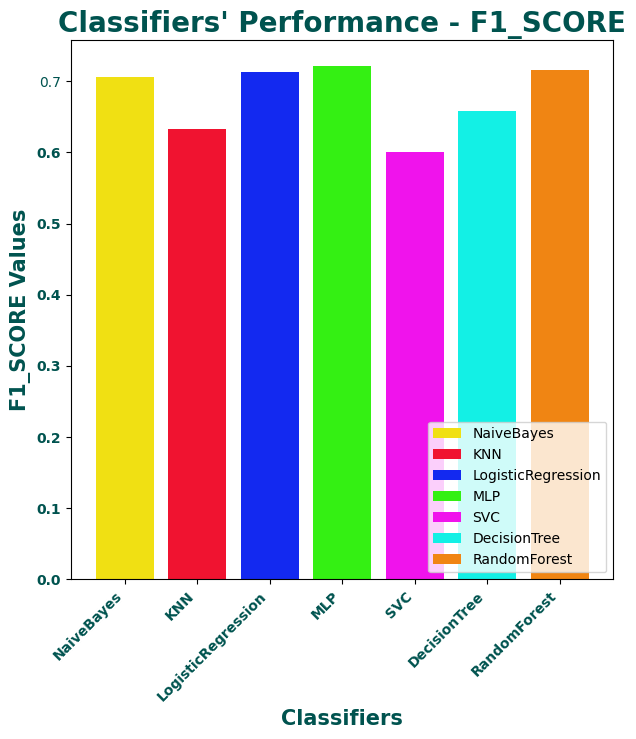

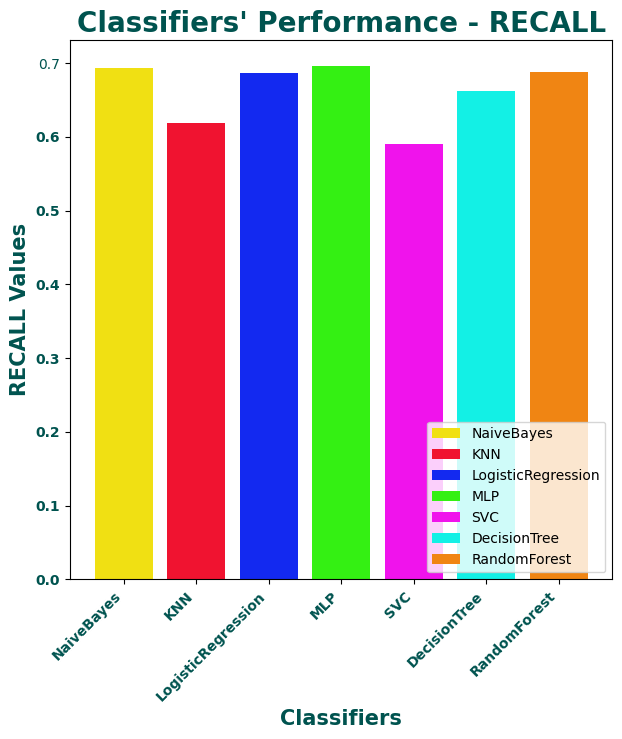

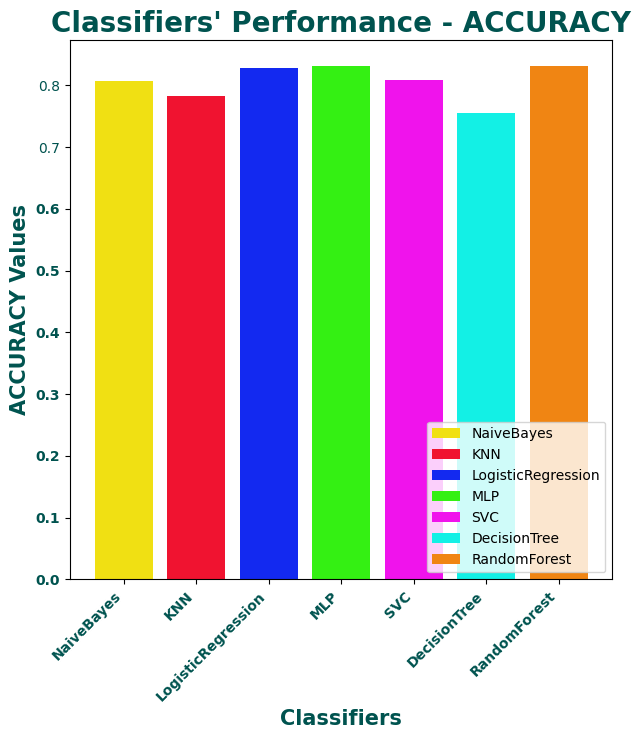

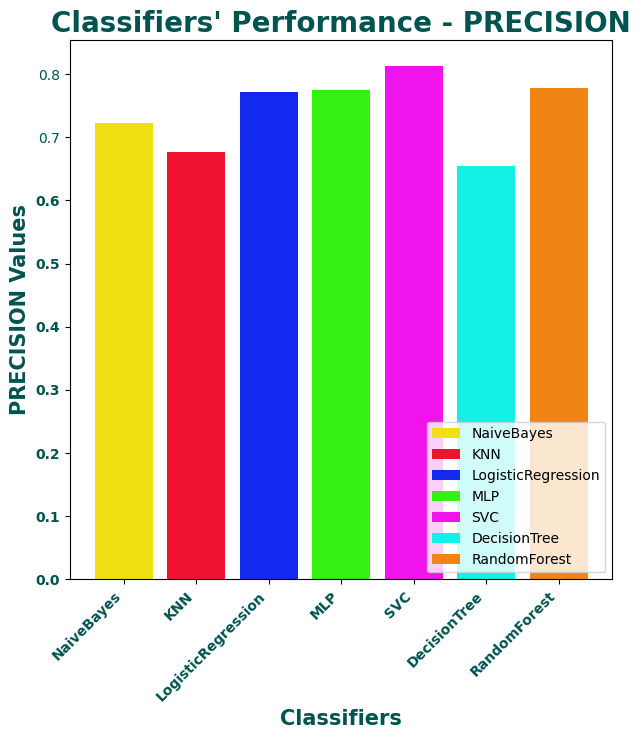

In [ ]:
for i in performance_results.keys():
    create_bar_plot(performance_results, i)


## 4d.ii Confusion Matrices

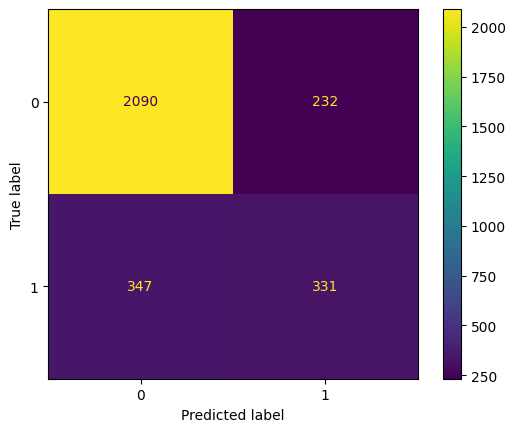

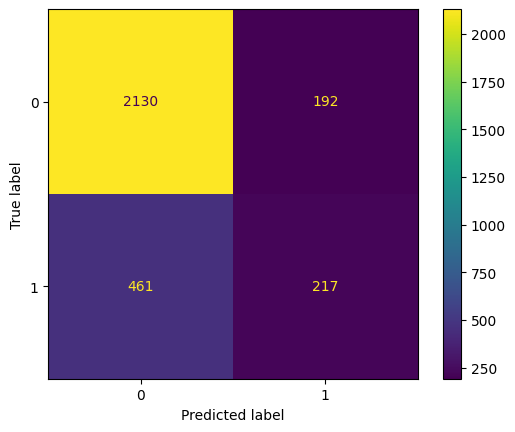

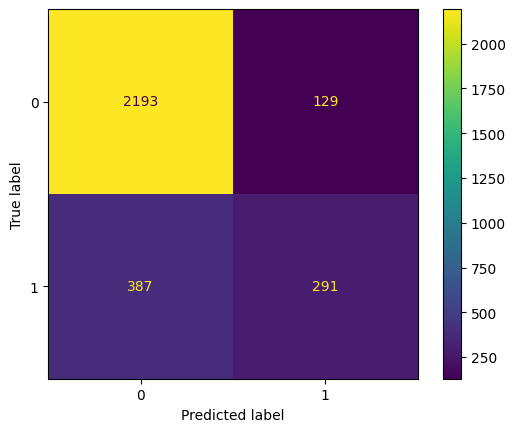

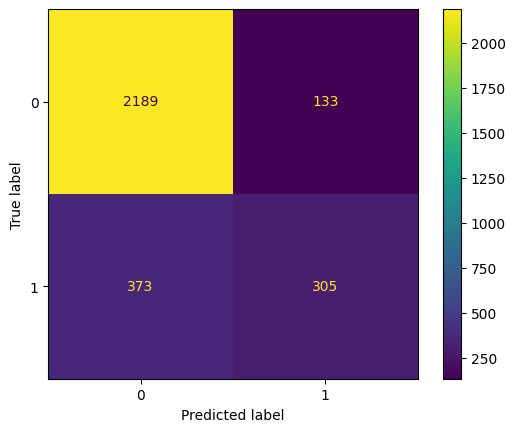

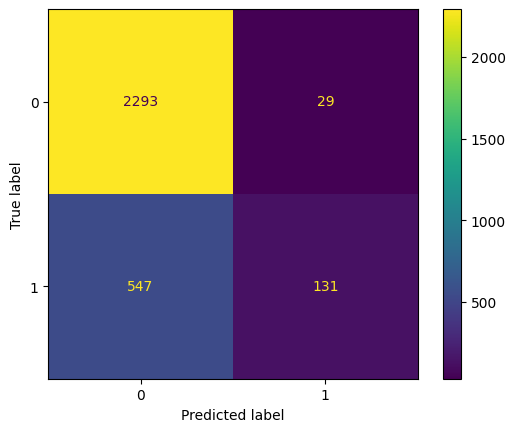

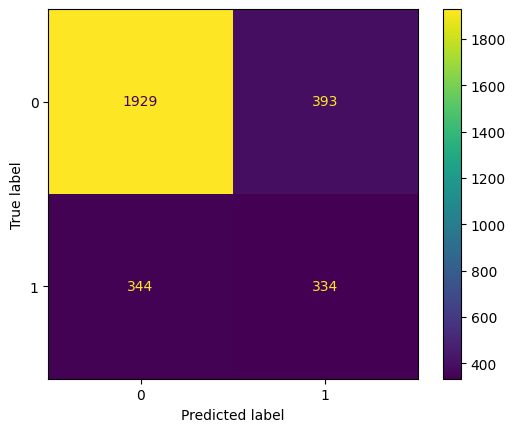

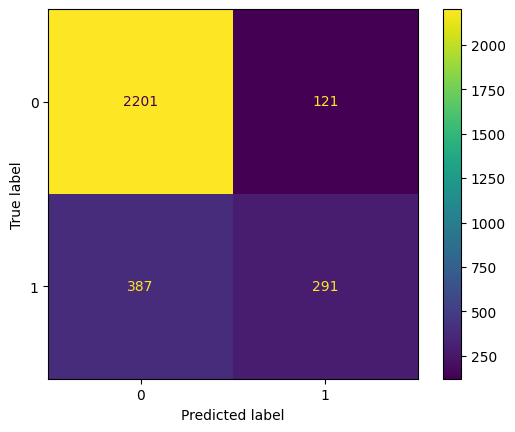

In [ ]:
#Confusion Matrices for the performance of each classifier
for name, classifier in classifiers.items():
    cm = confusion_matrix(y_val,predictions[name])
    matrix = ConfusionMatrixDisplay(confusion_matrix=cm)
    matrix.plot()

**General Conclusions on the Performance of the Best and Worst Models**

First of all, as shown both by the score bar plots and the confusion matrices, the two best classifiers appear to be the MLP and the Random Forest, as they achieved the best balance between precision and recall (as reflected in their F1-score). Looking more closely at the confusion matrices of each, we can conclude that the MLP is perhaps the optimal model in this case. With 506 total errors, of which 373 were False Negatives (FN) (predicting that it would not rain when it actually did), it appears to be marginally better than the Random Forest, which makes 2 more errors than the MLP, with a total of 387 FNs (14 more than the MLP). Besides the error category, the MLP also excels in correct predictions, correctly predicting that it will rain when it actually rained 14 more times than the Random Forest. Overall, the models seem to have trained quite well, with their main issue being the presence of FNs. This seems to be due either to the sample size or to the class imbalance. More specifically, we had a relatively small dataset with 7,683 "No" and 2,317 "Yes" instances in the "RainTomorrow" label. This led the model to train exceptionally well at correctly identifying the "No" class, but at the same time, the lack of more instances in the "Yes" class did not help it recognize True Positives (TP) as effectively. Whenever it was uncertain about the outcome, it opted for the "No" label (biased), simply because it was better trained on it.

Very important conclusions can also be drawn for the remaining classifiers that did not perform as well. More specifically, KNN and SVC, with F1-scores of 0.63 and 0.60 respectively, appear not to have performed as effectively during training. Their performance is noticeably worse—around 10% lower compared to the top models. They seem to have underfitted. They struggled to capture the non-linearity and complexity of the data, and being simpler models, they could not cope as effectively with the training.



## 5. Hyperparameter Tuning via Grid Search with 5-Fold Cross-Validation

To optimize classifier performance and maximize the positive class detection capability (F1-score), an exhaustive grid search is conducted using **Stratified 5-Fold Cross-Validation (`StratifiedKFold(n_splits=5)`)**.


## Classifiers' training with k-fold

Using K-Fold cross-validation, the optimized classifiers with the best hyperparameters will be found. The selection of the initial hyperparameters was made based on the needs of the classifiers.

In [ ]:
#  Dict with keys the Classifiers names and values the model and the hyperparameters of each classifier
def constract_classifiers()->Dict[str, BaseEstimator]:
    return {'NaiveBayes': {"model":gnbc, "params": {'var_smoothing': [10e-9, 10e-8,10e-5]}},
            'KNN': {"model":knn, "params": {'n_neighbors': [7, 9, 15]}},  # the number of neighbours
            'LogisticRegression': {"model":lgr, "params": {'tol': [10e-4, 10e-5, 10e-6], # Tolerance for stopping criteria
                                                           'max_iter':[500, 700]} # Maximum iterations for the solver to converge
                                  },
            'MLP': {"model":mlp, "params": {'activation': ['relu', 'logistic'],     # The function that "fires" a neuron
                                        'batch_size': [32, 64],     # How many samples to process in each training step
                                        'early_stopping': [True],      # Stops training if performance stops improving
                                        'hidden_layer_sizes': [100, 200],       # number of  neurons per hidden layer
                                        'learning_rate_init': [0.001, 0.0005]}},  # the learning speed of the model
            'SVC': {"model":svc, "params": {'degree': [2, 3],       # The degree of the polynomial (For 'poly')
                                                'kernel': ['rbf','linear', 'poly'],       # The type of "separator" (mapping function)
                                                'gamma' : ['scale'],    # (For 'rbf'or 'poly') How strict the decision boundary is
                                                'tol': [10e-4, 10e-5, 10e-6],      # Tolerance for stopping criteria
                                                'C':[0.1, 1, 10],  # classification errors penalty (regularization)
                                                'max_iter':[500, 700, 1000]   # Maximum iterations
                                                }},
            'DecisionTree': {"model":dtr, "params": {'max_depth': [5, 10, 15],   # The maximum depth, the levels of the tree
                                                'max_features': [None, 'sqrt'],    # How many features to check at each split
                                                'min_samples_leaf': [1, 2]}},  # Minimum number of samples required in a "leaf"
            'RandomForest': {"model":rdmf, "params": {'min_samples_leaf': [1, 2],  # Minimum number of samples in a final "leaf"
                                'n_estimators': [100, 200],   #number of trees in the forest
                                'max_features': ['sqrt', 'log2']  # How many features each tree checks at each split
                                }}
           }

In [ ]:
classifiers = constract_classifiers()
for classifier_nm, classifier in classifiers.items():
    cv_model = GridSearchCV(classifier['model'], classifier['params'], cv=5, refit=True, return_train_score=True)# create the  gridsearch object
    cv_model.fit(X_train, y_train) #train each classifier with every possible combination of the hyperparameters
    classifier['model'] = cv_model.best_estimator_  # replace with the best model
    classifier['params'] = cv_model.best_params_    # store the best parameters
    classifier['cv_results'] = cv_model.cv_results_ #the results of each split for each fold

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=500).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=500).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=500).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=500).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=500).  Consider pre-

##Prediction with the validation set

In [ ]:
classifiers #The new (optimal) classifiers with their optimal hyperparamaters

{'NaiveBayes': {'model': GaussianNB(var_smoothing=0.0001),
  'params': {'var_smoothing': 0.0001},
  'cv_results': {'mean_fit_time': array([0.00432343, 0.00573282, 0.00633364]),
   'std_fit_time': array([0.00037533, 0.00066635, 0.00034025]),
   'mean_score_time': array([0.00198331, 0.00313549, 0.0031435 ]),
   'std_score_time': array([7.95784789e-05, 2.17385840e-04, 2.08894702e-04]),
   'param_var_smoothing': masked_array(data=[1e-08, 1e-07, 0.0001],
                mask=[False, False, False],
          fill_value=1e+20),
   'params': [{'var_smoothing': 1e-08},
    {'var_smoothing': 1e-07},
    {'var_smoothing': 0.0001}],
   'split0_test_score': array([0.78642857, 0.78642857, 0.79      ]),
   'split1_test_score': array([0.80357143, 0.80357143, 0.80142857]),
   'split2_test_score': array([0.79785714, 0.79785714, 0.79928571]),
   'split3_test_score': array([0.78214286, 0.78214286, 0.78214286]),
   'split4_test_score': array([0.79714286, 0.79714286, 0.79571429]),
   'mean_test_score': arra

In [ ]:
predictions={} # New predictions with the  validion set, using the new, optimal  classifiers
for name, classifier in classifiers.items():
    predictions[name]=classifier['model'].predict(X_val)
print(predictions)

{'NaiveBayes': array([0., 0., 1., ..., 0., 0., 1.]), 'KNN': array([0., 0., 1., ..., 1., 0., 1.]), 'LogisticRegression': array([0., 0., 0., ..., 1., 0., 0.]), 'MLP': array([0., 0., 0., ..., 1., 0., 0.]), 'SVC': array([0., 0., 0., ..., 0., 0., 0.]), 'DecisionTree': array([0., 0., 0., ..., 0., 0., 1.]), 'RandomForest': array([0., 0., 0., ..., 1., 0., 0.])}


## pred vs y_val

In [ ]:
#dataFrame for the  f1-score of the new classifiers
f1={}
for name, v_predictions in predictions.items():
    f1[name]=f1_score(y_val,v_predictions, average='macro')
pd.DataFrame.from_dict(f1, orient='index', columns=['F1-Score'])


,F1-Score
NaiveBayes,0.707663
KNN,0.609741
LogisticRegression,0.712396
MLP,0.699628
SVC,0.639797
DecisionTree,0.691393
RandomForest,0.708991


## General model performance

In [ ]:
#dataFrame  for the general performance of the new (optimal) classifiers with the new predictions
f1={}
recall={}
precision={}
accuracy={}
performance_results={}
for name, v_predictions in predictions.items():
    f1[name]=f1_score(y_val,v_predictions, average='macro')
    recall[name]= recall_score(y_val,v_predictions, average='macro')
    accuracy[name]=accuracy_score(y_val,v_predictions)
    precision[name]=precision_score(y_val,v_predictions, average='macro')
performance_results={"F1_SCORE":f1,"RECALL":recall,"ACCURACY":accuracy,"PRECISION":precision}
RESULTS=pd.DataFrame.from_dict(performance_results, orient='index')
print(RESULTS)

           NaiveBayes       KNN  LogisticRegression       MLP       SVC  \
F1_SCORE     0.707663  0.609741            0.712396  0.699628  0.639797   
RECALL       0.697981  0.596794            0.686824  0.675514  0.622261   
ACCURACY     0.805667  0.789667            0.828000  0.821000  0.794333   
PRECISION    0.720619  0.696937            0.771429  0.757570  0.703992   

           DecisionTree  RandomForest  
F1_SCORE       0.691393      0.708991  
RECALL         0.667618      0.683659  
ACCURACY       0.817667      0.826333  
PRECISION      0.752136      0.768438  


## Bar-plots

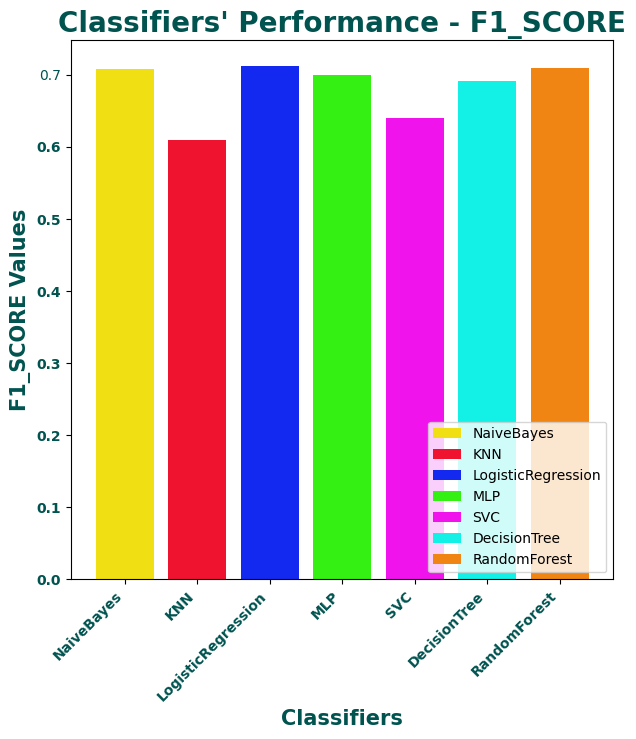

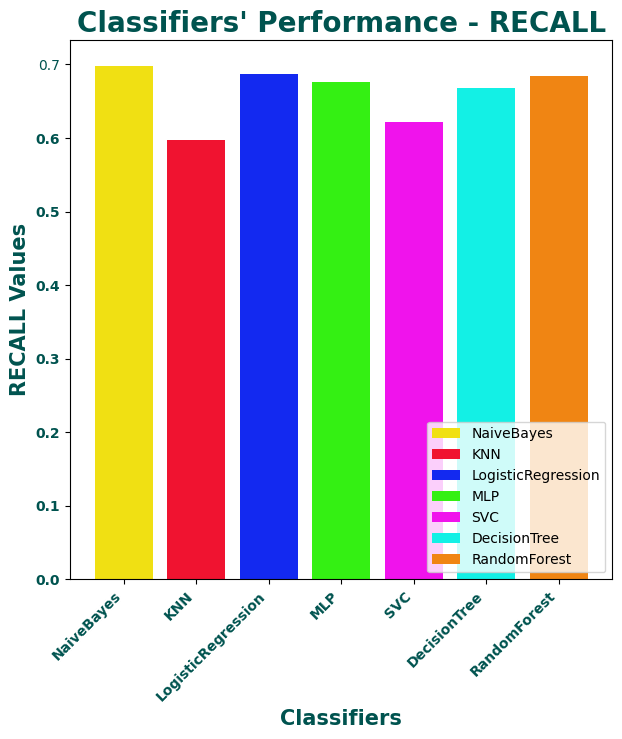

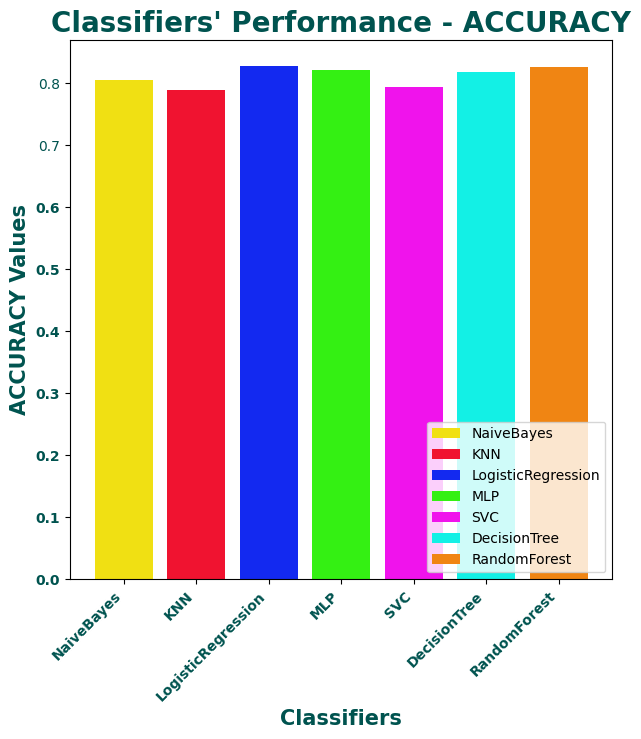

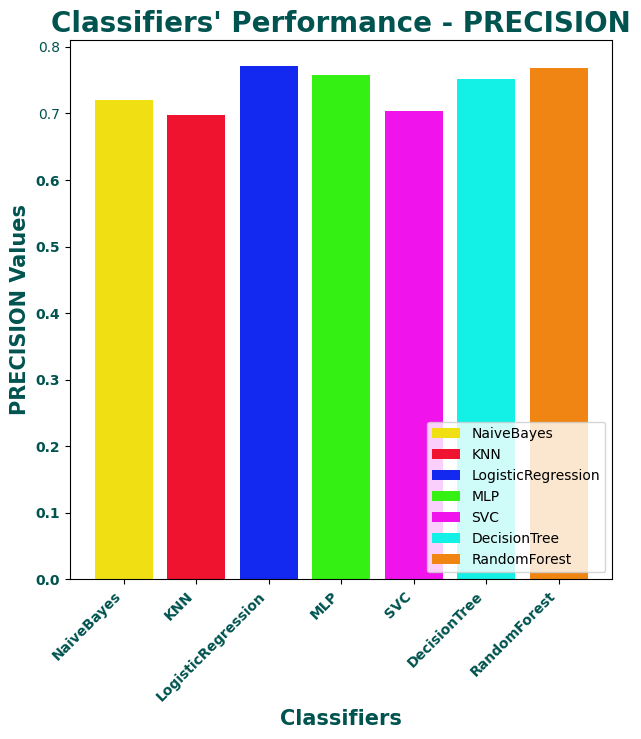

In [ ]:
for i in performance_results.keys():
    create_bar_plot(performance_results, i)


## Confusion Matrices

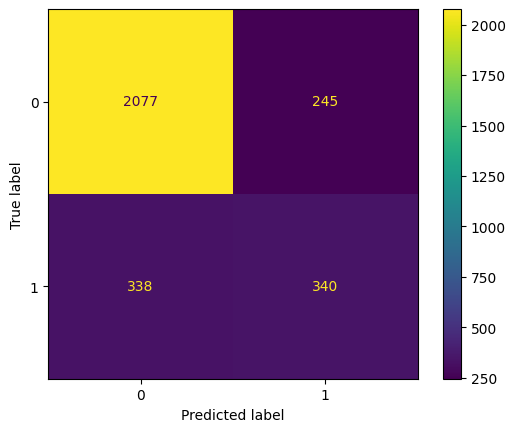

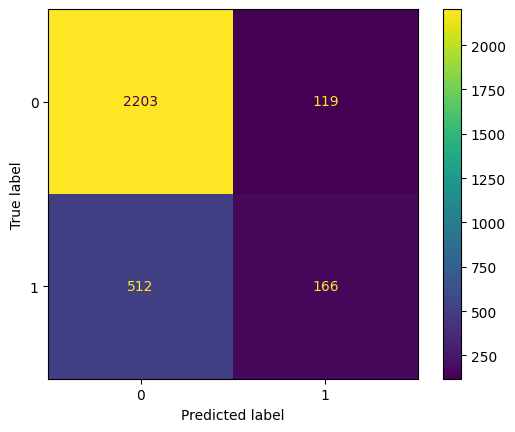

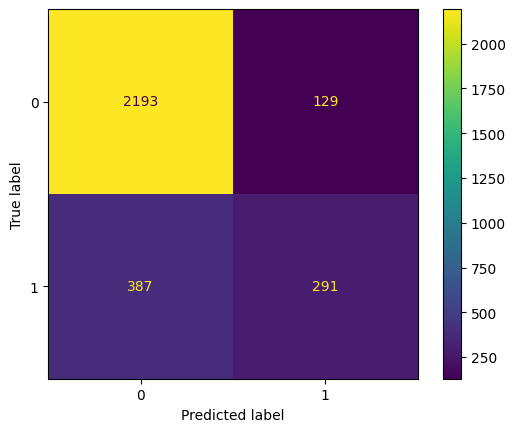

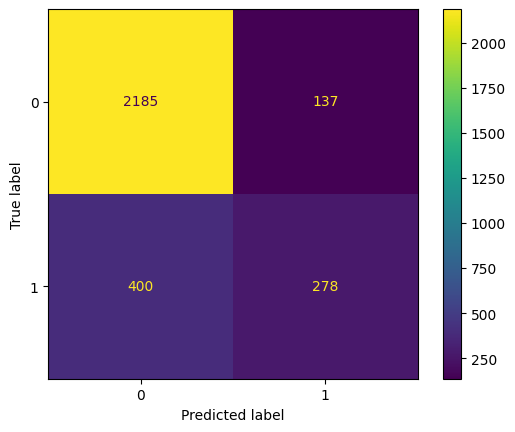

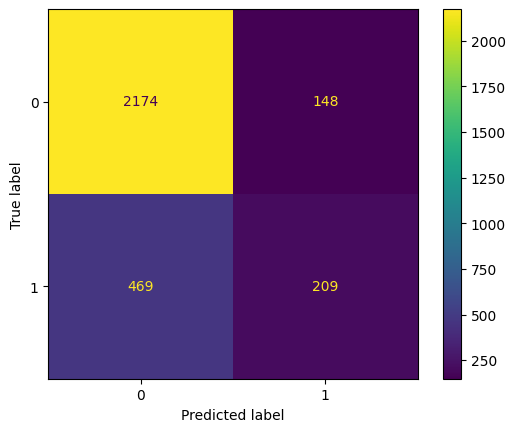

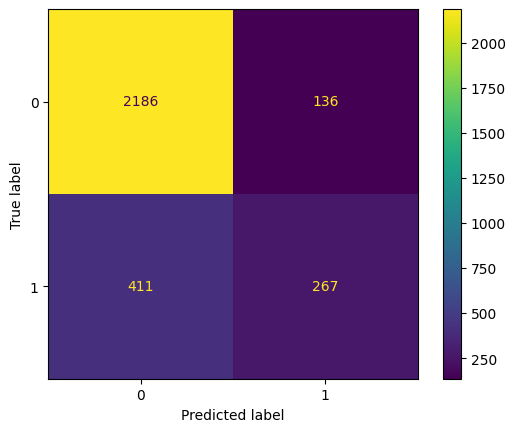

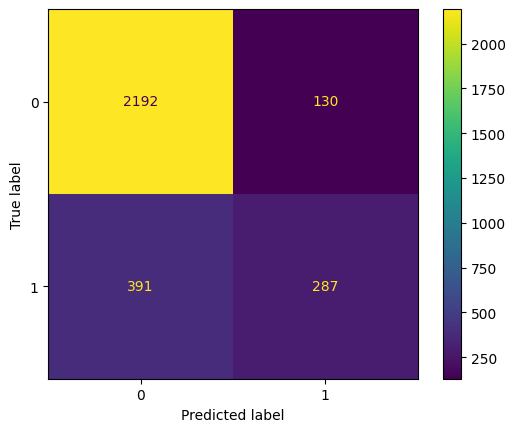

In [ ]:
##Confusion matrices for performance_results
for name, classifier in classifiers.items():
    cm = confusion_matrix(y_val,classifier['model'].predict(X_val))
    matrix = ConfusionMatrixDisplay(confusion_matrix=cm)
    matrix.plot()


As shown in the plots above, the models that benefited the most from the grid search were mainly the Decision Tree and SVC. These two had the greatest improvement, especially in their F1-scores (from 0.657527 to 0.691393 and from 0.600532 to 0.639797, respectively). This indicates that their initial parameters were far from ideal, and after the 5-fold cross-validation, much better configurations were found. It appears that tuning 'kernel' and 'C' for the SVC, as well as 'max_depth' and 'min_samples_leaf' for the Decision Tree, played a pivotal role.

On the other hand, a drop is observed in the MLP and Random Forest—which, prior to the grid search, were the top-performing classifiers. This is not necessarily a bad thing and—as shown below—suggests that the initial models were overfitted to the training data. The grid search identified parameters that lead to better generalization, even if the score on this specific dataset suggested otherwise.

It is also important to be mentiones that Logistic Regression maintained its already very strong performance and emerges as the best choice of classifier. This is further confirmed by its confusion matrix.

## TRAIN PREDICTIONS

In [ ]:
train_predictions={} #predictions with the train-set
for name, classifier in classifiers.items():
    train_predictions[name]=classifier['model'].predict(X_train)
print(train_predictions)

{'NaiveBayes': array([0., 0., 0., ..., 0., 0., 1.]), 'KNN': array([0., 0., 0., ..., 0., 0., 1.]), 'LogisticRegression': array([0., 0., 0., ..., 0., 0., 1.]), 'MLP': array([0., 0., 0., ..., 0., 0., 1.]), 'SVC': array([0., 0., 0., ..., 0., 0., 1.]), 'DecisionTree': array([0., 0., 0., ..., 0., 0., 1.]), 'RandomForest': array([0., 0., 0., ..., 0., 0., 1.])}


In [ ]:
#Gernal performane of the models' predictions with the train-set
f1={}
recall={}
precision={}
accuracy={}
performance_results={}
for name, tr_predictions in train_predictions.items():
    f1[name]=f1_score(y_train,tr_predictions, average='macro')
    recall[name]= recall_score(y_train,tr_predictions, average='macro')
    accuracy[name]=accuracy_score(y_train,tr_predictions)
    precision[name]=precision_score(y_train,tr_predictions, average='macro')
performance_results={"F1_SCORE":f1,"RECALL":recall,"ACCURACY":accuracy,"PRECISION":precision}
RESULTS=pd.DataFrame.from_dict(performance_results, orient='index')
print(RESULTS)

           NaiveBayes       KNN  LogisticRegression       MLP       SVC  \
F1_SCORE     0.699314  0.656866            0.714036  0.714055  0.637920   
RECALL       0.690633  0.634277            0.689801  0.688827  0.620882   
ACCURACY     0.794429  0.809000            0.823000  0.824429  0.790429   
PRECISION    0.710955  0.767540            0.769057  0.773796  0.710041   

           DecisionTree  RandomForest  
F1_SCORE       0.730959      0.967875  
RECALL         0.702905      0.952834  
ACCURACY       0.835286      0.977714  
PRECISION      0.796649      0.985361  


## SCATTER PLOTS FOR DEVIATION, OVERFITTING, UNDERFITTING.

This function returns scatter plots. In general, the purpose of these plots is to visualize and understand the variance, as well as the overfitting and underfitting of a model. The x-axis represents each distinct hyperparameter combination for each classifier, while the y-axis varies depending on the plot.

More specifically, in the 'standard deviation' plot, the y-axis displays the 'std_test_score' (blue dots) and 'std_train_score' (red dots). The closer the values of the blue dots are, the more we can conclude that the model is characterized by stability. The greater the difference between the values, the more the model is characterized by high variance.

In the second plot (mean score from CV search), the 'mean_test_score' is shown alongside the 'mean_train_score'. From the distance between the respective dots on each vertical line, we can draw conclusions regarding overfitting or underfitting. If the 'mean_train_score' values are high while the 'mean_test_score' values are much lower, we infer that the respective model is overfitting. Graphically, this corresponds to the blue and red dots on a given vertical line being far apart from each other. Similarly, we can draw visual conclusions for the case of underfitting.

Although these plots were not explicitly requested, I consider them an easy and intuitive way to address more general questions regarding the problem.

In [ ]:
def plot_scores(title, classifier)-> None: #Helpful scatter plots for the visualisation of the overfitting or the underfitting of a model, and it's deviation
    classifier_nm, classifier = classifier
    plt.figure(figsize=(6, 6))
    plt.gcf().set_facecolor("#dbd9ec")
    plt.gca().set_facecolor("#dafeff")
    # plt.plot(x, y, 'o--', color='#860436', linewidth=2)
    # plt.plot(x_test, y_est, 'o-', color='#4bc0ad', linewidth=2)
    plt.title(classifier_nm + ' - ' + title, fontsize=12,color='#00534f', fontdict={'weight':'bold'})

    x = [i for i in range(1,len(classifier['cv_results']['std_test_score'].tolist())+1)]

    if title.lower() == 'standard deviation':
        y_test=classifier['cv_results']['std_test_score']
        y_train=classifier['cv_results']['std_train_score']
    else:   # mean score from CV search
        y_test=classifier['cv_results']['mean_test_score']
        y_train=classifier['cv_results']['mean_train_score']

    plt.scatter(x,y_test , color='blue', label='Test Data')
    plt.scatter(x,y_train , color='red', label='Train Data')
    plt.xlabel("# of CV Parameters Combination", fontsize=14, color='#a04899', fontdict={'weight':'bold'})
    plt.ylabel(title, fontsize=14, color='#a04899', fontdict={'weight':'bold'})

    plt.legend(['y_test', 'y_train'], loc ="lower right")
    # plt.errorbar(x, y_est, yerr = np.var(y_est), ecolor='m')
    plt.grid(True)
    plt.show()
    return

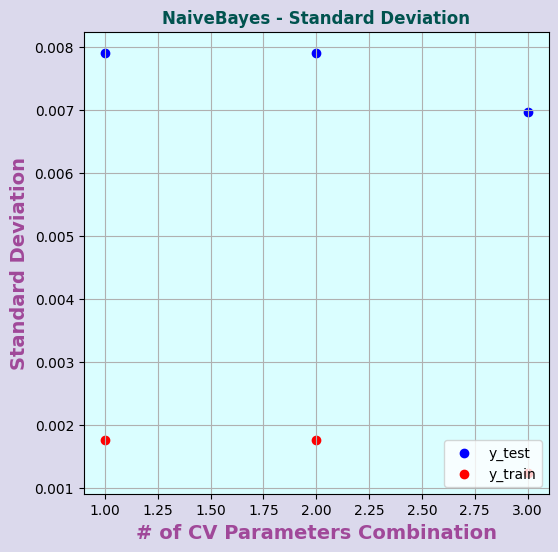

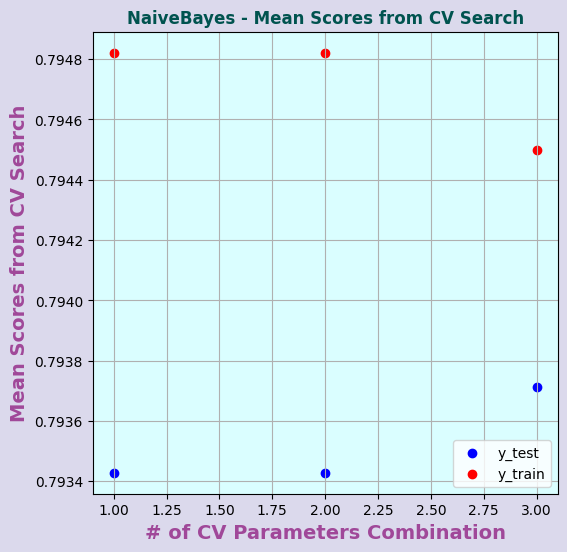

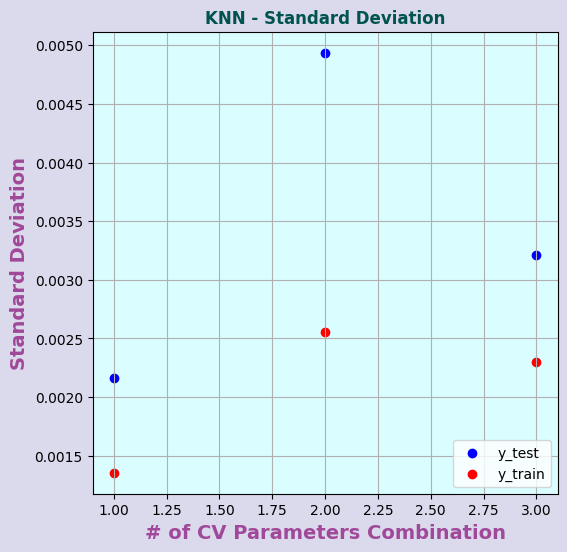

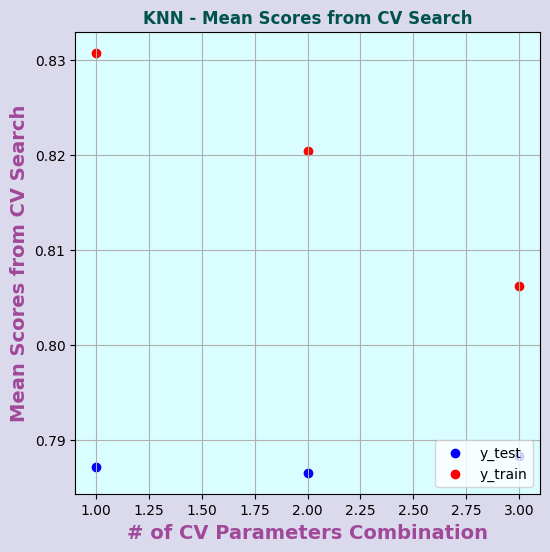

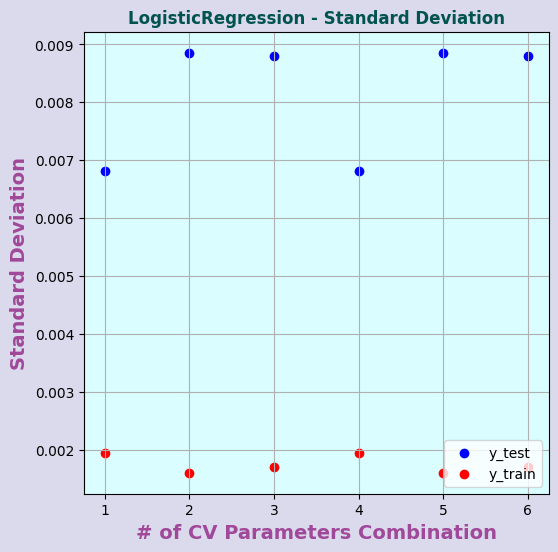

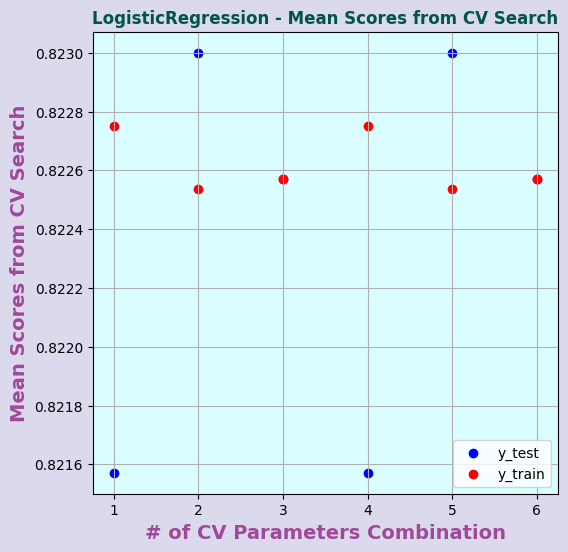

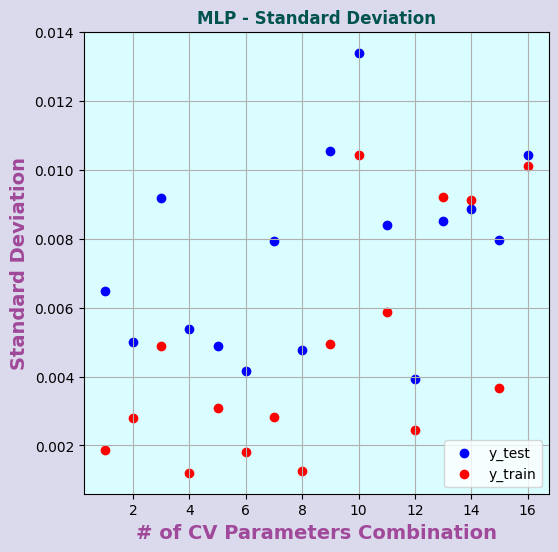

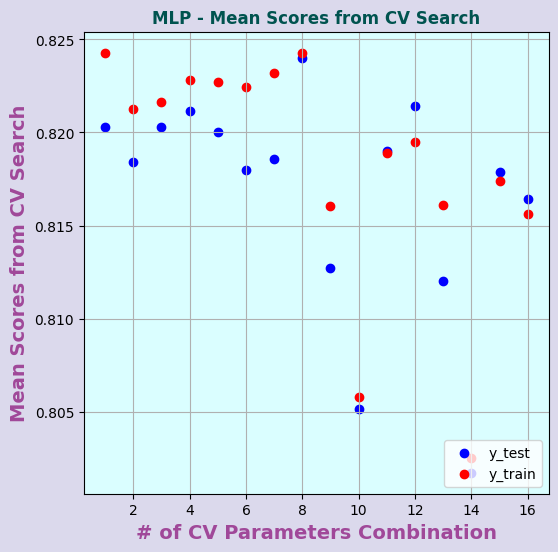

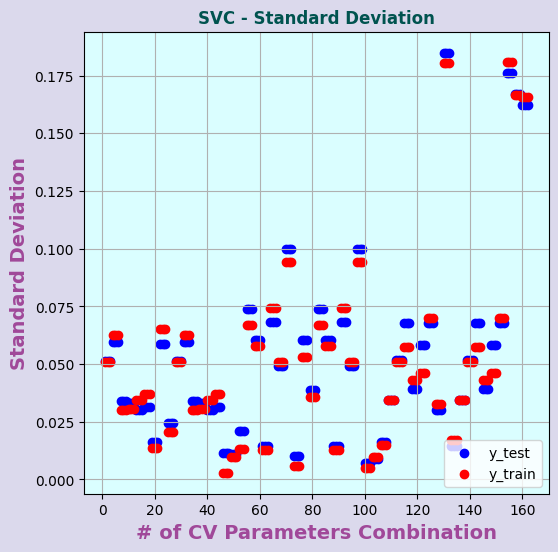

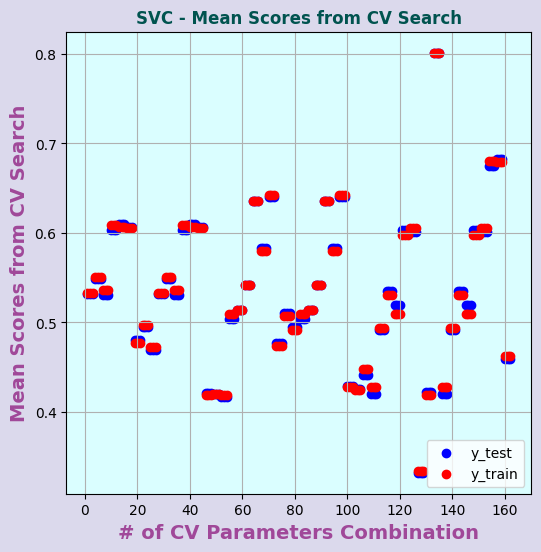

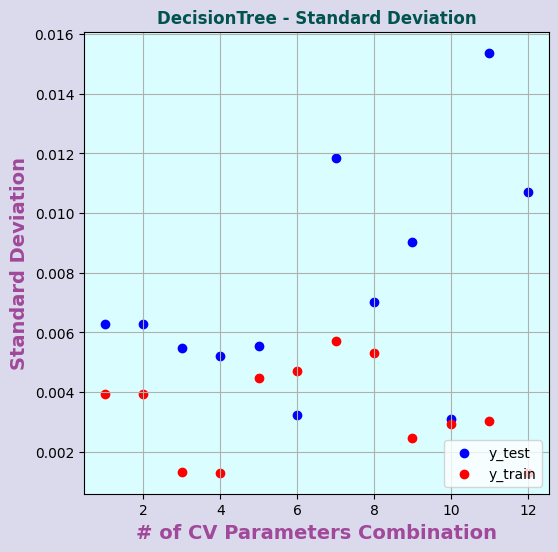

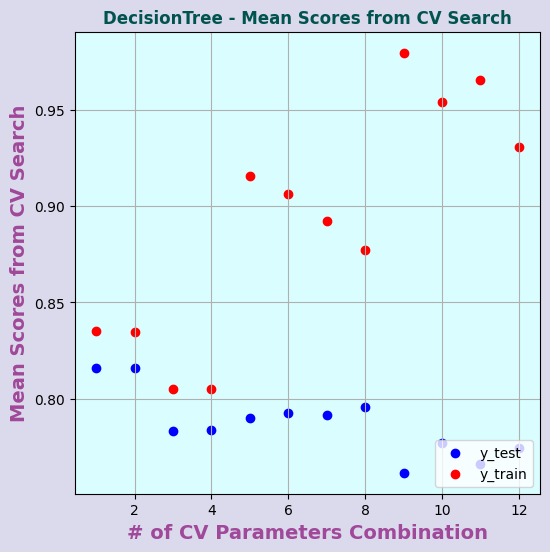

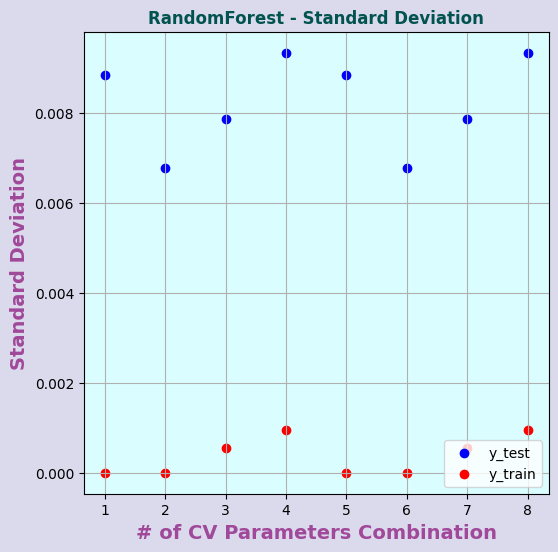

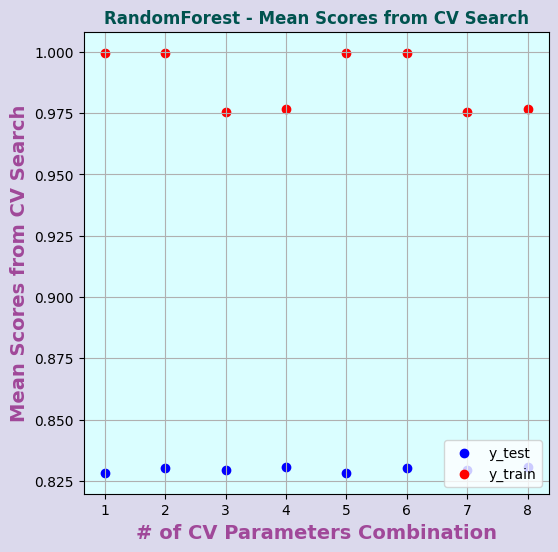

In [ ]:
for cl in classifiers.items():
    plot_scores("Standard Deviation", cl)
    plot_scores("Mean Scores from CV Search", cl)

#standard deviation

With the table below, we can draw useful conclusions regarding the standard deviation of the classifiers. The std_results DataFrame presents the variance exhibited by the classifiers (using their best hyperparameter combination) across the 5 folds.

In [ ]:
std_results = []
for classifier_nm, classifier in classifiers.items():
    cv_results = classifier['cv_results'] #cross validation results
    best_index = np.argmin(cv_results['rank_test_score']) # the best hyperprameter combination as an index
    best_std = cv_results['std_test_score'][best_index] #std-test score of the classifier with the best hyperparameter combination
    std_results.append({'Classifier': classifier_nm, 'Std': best_std})
std_results_df = pd.DataFrame(std_results).sort_values(by='Std', ascending=False)
print(std_results_df)

           Classifier       Std
4                 SVC  0.014407
6        RandomForest  0.009335
2  LogisticRegression  0.008857
0          NaiveBayes  0.006961
5        DecisionTree  0.006269
3                 MLP  0.004772
1                 KNN  0.003213


##6. Performance Evaluation of Optimized Models

We will now apply the seven optimized classifiers to the samples of the test set (without its labels) to generate predictions.

## Fixing the test set

Initially, an Exploratory Data Analysis (EDA) must be performed on the new test set in the exact same manner as in the original dataset. This will be done with the help of the functions created during the processing of the train dataset.

### Load the test set

In [ ]:
# test_dat_url = ''   # replace with your own file path
test_data_url ='/content/gdrive/MyDrive/Colab Notebooks/test.csv'
test_data=load_data(test_data_url)

In [ ]:
print(test_data)

            Date Location  MinTemp  MaxTemp  Rainfall  Evaporation  Sunshine  \
0     14/08/2016   Albury      4.7     16.6       0.2          NaN       NaN   
1     15/08/2016   Albury      2.2     16.8       0.0          NaN       NaN   
2     26/08/2016   Albury      0.2     13.6       0.0          NaN       NaN   
3     29/08/2016   Albury      3.4     18.2       0.0          NaN       NaN   
4     07/09/2016   Albury      5.5     20.5       0.0          NaN       NaN   
...          ...      ...      ...      ...       ...          ...       ...   
4595  06/04/2016    Uluru     19.1     33.2       0.0          NaN       NaN   
4596  23/04/2016    Uluru     16.9     28.4       0.0          NaN       NaN   
4597  14/05/2016    Uluru      7.4     27.8       0.0          NaN       NaN   
4598  11/06/2016    Uluru      7.2     17.4       0.0          NaN       NaN   
4599  11/06/2016    Uluru      7.3     23.4       0.0          NaN       NaN   

     WindGustDir  WindGustSpeed WindDir

### Label names for the test set

In [ ]:
test_label_names=get_label_names(test_data)
print(label_names)

['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'RainTomorrow']


###Changes and new features

In [ ]:
columns_config = {"Mean_Temp": ("MaxTemp", "MinTemp"),
                  "Ps_mean":("Pressure9am","Pressure3pm"),
                  "Ws_mean":("WindSpeed9am","WindSpeed3pm"),
                  "Temp_mean":("Temp9am","Temp3pm"),
                  "Humid_mean":("Humidity9am","Humidity3pm"),
                  "Cloud_mean":("Cloud9am","Cloud3pm")
                  }

test_data = get_month_number_column(test_data)
test_data = create_mean_features(test_data, columns_config)
print(test_data)

           Date Location  MinTemp  MaxTemp  Rainfall  Evaporation  Sunshine  \
0    2016-08-14   Albury      4.7     16.6       0.2          NaN       NaN   
1    2016-08-15   Albury      2.2     16.8       0.0          NaN       NaN   
2    2016-08-26   Albury      0.2     13.6       0.0          NaN       NaN   
3    2016-08-29   Albury      3.4     18.2       0.0          NaN       NaN   
4    2016-07-09   Albury      5.5     20.5       0.0          NaN       NaN   
...         ...      ...      ...      ...       ...          ...       ...   
4595 2016-06-04    Uluru     19.1     33.2       0.0          NaN       NaN   
4596 2016-04-23    Uluru     16.9     28.4       0.0          NaN       NaN   
4597 2016-05-14    Uluru      7.4     27.8       0.0          NaN       NaN   
4598 2016-11-06    Uluru      7.2     17.4       0.0          NaN       NaN   
4599 2016-11-06    Uluru      7.3     23.4       0.0          NaN       NaN   

     WindGustDir  WindGustSpeed WindDir9am  ... Tem

###Dropping features

In [ ]:
cols_to_drop=("Date", 'MinTemp', 'MaxTemp', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm',"Evaporation",'Sunshine')
test_data = drop_columns(test_data,cols_to_drop)
print(test_data)

     Location  Rainfall WindGustDir  WindGustSpeed WindDir9am WindDir3pm  \
0      Albury       0.2           W           22.0          E          W   
1      Albury       0.0         ENE           19.0        NaN        ESE   
2      Albury       0.0         WNW           30.0        ESE          W   
3      Albury       0.0         NNE           26.0        NaN          N   
4      Albury       0.0           E           22.0        NaN        ESE   
...       ...       ...         ...            ...        ...        ...   
4595    Uluru       0.0         SSE           37.0        SSE          S   
4596    Uluru       0.0           E           31.0        ESE        ESE   
4597    Uluru       0.0          NE           20.0        ESE          E   
4598    Uluru       0.0          NE            NaN        NaN        NaN   
4599    Uluru       0.0          NE            NaN        NaN        NaN   

     RainToday RainTomorrow  Month_number  Mean_Temp  Ps_mean  Ws_mean  \
0           N

###  Replacing missing values

In [ ]:
find_null_data(test_data)

Location            0
Rainfall          125
WindGustDir       330
WindGustSpeed     327
WindDir9am        253
WindDir3pm        117
RainToday         125
RainTomorrow      132
Month_number        0
Mean_Temp          64
Ps_mean           364
Ws_mean            99
Temp_mean         124
Humid_mean        177
Cloud_mean       1927
dtype: int64


In [ ]:
test_data = replace_missing_vals(test_data)
test_data

,Location,Rainfall,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,RainToday,RainTomorrow,Month_number,Mean_Temp,Ps_mean,Ws_mean,Temp_mean,Humid_mean,Cloud_mean
0,Albury,0.2,W,22.0,E,W,No,No,8,10.65,1028.85,8.5,13.00,68.5,5.0
1,Albury,0.0,ENE,19.0,N,ESE,No,No,8,9.50,1031.55,5.5,11.10,78.0,4.5
2,Albury,0.0,WNW,30.0,ESE,W,No,No,8,6.90,1021.70,13.0,8.50,75.0,4.5
3,Albury,0.0,NNE,26.0,N,N,No,No,8,10.80,1025.90,4.5,13.25,68.0,4.5
4,Albury,0.0,E,22.0,N,ESE,No,No,7,13.00,1029.30,3.5,15.90,75.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4595,Uluru,0.0,SSE,37.0,SSE,S,No,No,6,26.15,1014.70,25.0,27.90,39.5,5.0
4596,Uluru,0.0,E,31.0,ESE,ESE,No,No,4,22.65,1021.60,20.0,23.75,35.0,5.0
4597,Uluru,0.0,NE,20.0,ESE,E,No,No,5,17.60,1020.75,6.5,20.35,37.5,5.0
4598,Uluru,0.0,NE,37.0,N,W,No,No,11,12.30,1029.05,15.5,13.55,57.0,5.0


###Replacing categorical values

In [ ]:
test_data = replace_categorical_values(test_data)
print(test_data)

      Location  Rainfall  WindGustDir  WindGustSpeed  WindDir9am  WindDir3pm  \
0            0       0.2            0           22.0           4           0   
1            0       0.0            1           19.0          12           9   
2            0       0.0            2           30.0           9           0   
3            0       0.0            3           26.0          12          12   
4            0       0.0            4           22.0          12           9   
...        ...       ...          ...            ...         ...         ...   
4595        48       0.0           13           37.0          13          11   
4596        48       0.0            4           31.0           9           9   
4597        48       0.0            6           20.0           9           4   
4598        48       0.0            6           37.0          12           0   
4599        48       0.0            6           37.0          12           0   

      RainToday  RainTomorrow  Month_nu

### Scaling values

In [ ]:
test_data= get_scaled_values(test_data)
print(test_data)

      Location  Rainfall  WindGustDir  WindGustSpeed  WindDir9am  WindDir3pm  \
0          0.0  0.001145     0.000000       0.118280    0.266667    0.000000   
1          0.0  0.000000     0.066667       0.086022    0.800000    0.600000   
2          0.0  0.000000     0.133333       0.204301    0.600000    0.000000   
3          0.0  0.000000     0.200000       0.161290    0.800000    0.800000   
4          0.0  0.000000     0.266667       0.118280    0.800000    0.600000   
...        ...       ...          ...            ...         ...         ...   
4595       1.0  0.000000     0.866667       0.279570    0.866667    0.733333   
4596       1.0  0.000000     0.266667       0.215054    0.600000    0.600000   
4597       1.0  0.000000     0.400000       0.096774    0.600000    0.266667   
4598       1.0  0.000000     0.400000       0.279570    0.800000    0.000000   
4599       1.0  0.000000     0.400000       0.279570    0.800000    0.000000   

      RainToday  RainTomorrow  Month_nu

### test_labels and test_features

In [ ]:
#New features and Labels for the test-set
test_features, test_label = set_labels_features(test_data)


In [ ]:
classifiers

{'NaiveBayes': {'model': GaussianNB(var_smoothing=0.0001),
  'params': {'var_smoothing': 0.0001},
  'cv_results': {'mean_fit_time': array([0.00432343, 0.00573282, 0.00633364]),
   'std_fit_time': array([0.00037533, 0.00066635, 0.00034025]),
   'mean_score_time': array([0.00198331, 0.00313549, 0.0031435 ]),
   'std_score_time': array([7.95784789e-05, 2.17385840e-04, 2.08894702e-04]),
   'param_var_smoothing': masked_array(data=[1e-08, 1e-07, 0.0001],
                mask=[False, False, False],
          fill_value=1e+20),
   'params': [{'var_smoothing': 1e-08},
    {'var_smoothing': 1e-07},
    {'var_smoothing': 0.0001}],
   'split0_test_score': array([0.78642857, 0.78642857, 0.79      ]),
   'split1_test_score': array([0.80357143, 0.80357143, 0.80142857]),
   'split2_test_score': array([0.79785714, 0.79785714, 0.79928571]),
   'split3_test_score': array([0.78214286, 0.78214286, 0.78214286]),
   'split4_test_score': array([0.79714286, 0.79714286, 0.79571429]),
   'mean_test_score': arra

###Predictions with the test set

In [ ]:
# Predictions for the test-set with the optimal  classifiers as they have formed after the cross validation process.
tpredictions={}
for name , classifier in classifiers.items():
    tpredictions[name]=classifier['model'].predict(test_features)
print(tpredictions)

{'NaiveBayes': array([0., 0., 0., ..., 0., 0., 0.]), 'KNN': array([0., 0., 0., ..., 0., 0., 0.]), 'LogisticRegression': array([0., 0., 0., ..., 0., 0., 0.]), 'MLP': array([0., 0., 0., ..., 0., 0., 0.]), 'SVC': array([0., 0., 0., ..., 0., 0., 0.]), 'DecisionTree': array([0., 0., 0., ..., 0., 0., 0.]), 'RandomForest': array([0., 0., 0., ..., 0., 0., 0.])}


## Test predictions vs y_test with Precision and Recall

In [ ]:
# DATAFRAME for the general performance (recall, precision, f1-score) of the optimal  classifiers for the new test-set.
recall={}
precision={}
f1={}
performance_results={}
for name, test_predictions in tpredictions.items():
    recall[name]= recall_score(test_label,test_predictions, average='macro')
    precision[name]=precision_score(test_label,test_predictions, average='macro')
    f1[name]=f1_score(test_label,test_predictions, average='macro')
performance_results={"RECALL":recall,"PRECISION":precision,"F1":f1}
RESULTS=pd.DataFrame.from_dict(performance_results, orient='index')
print(RESULTS)

           NaiveBayes       KNN  LogisticRegression       MLP       SVC  \
RECALL       0.716044  0.609356            0.722312  0.738586  0.614242   
PRECISION    0.702808  0.696492            0.771496  0.762710  0.739519   
F1           0.708724  0.624234            0.741048  0.749146  0.631805   

           DecisionTree  RandomForest  
RECALL         0.686002      0.730829  
PRECISION      0.743195      0.768681  
F1             0.705423      0.746211  


## Bar plots

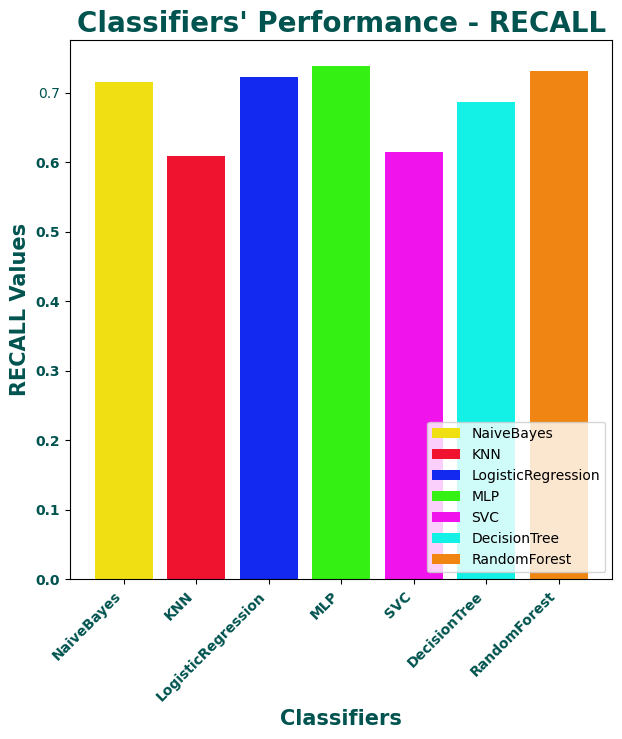

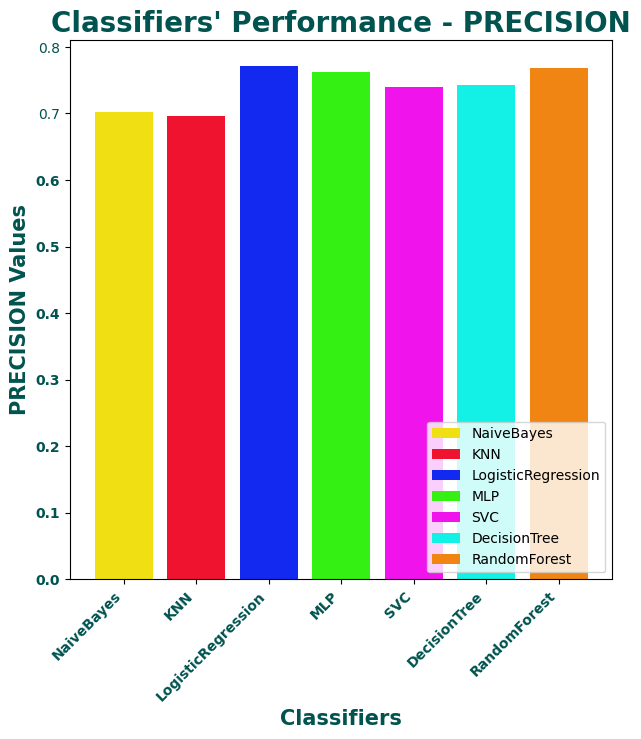

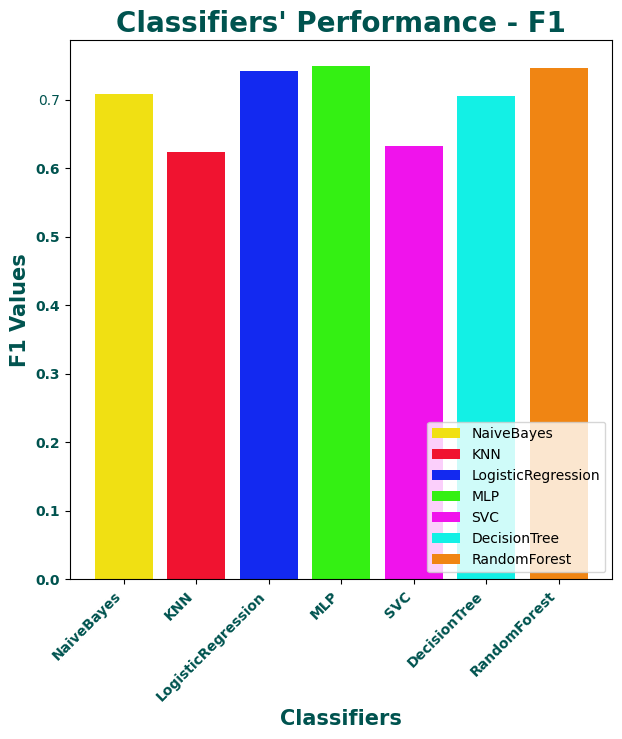

In [ ]:
# bar plots for data frame
for i in performance_results.keys():
    create_bar_plot(performance_results, i)

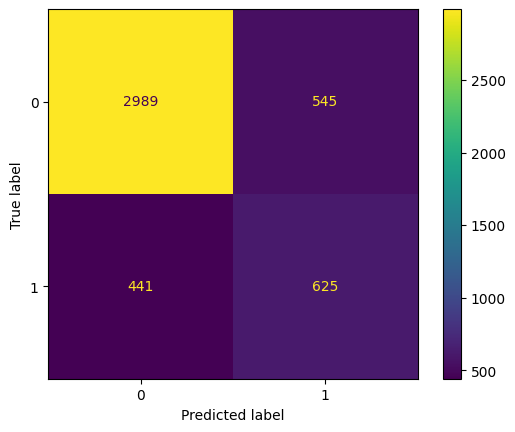

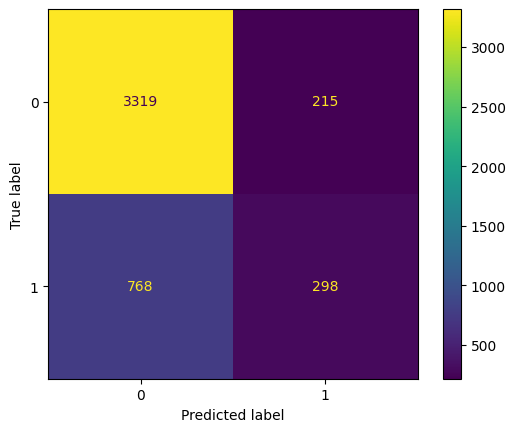

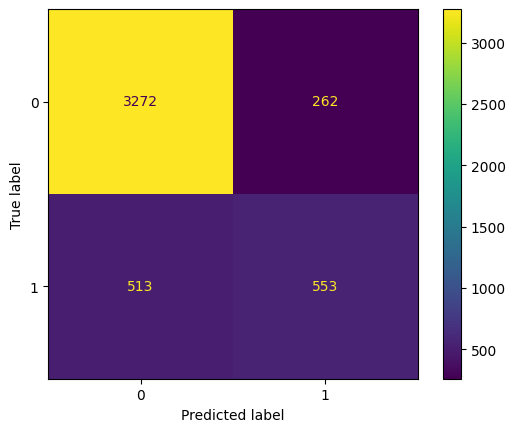

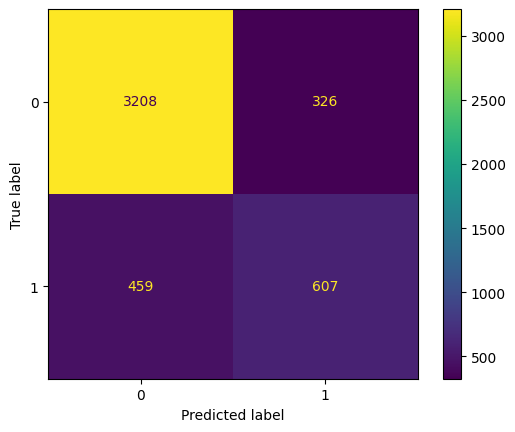

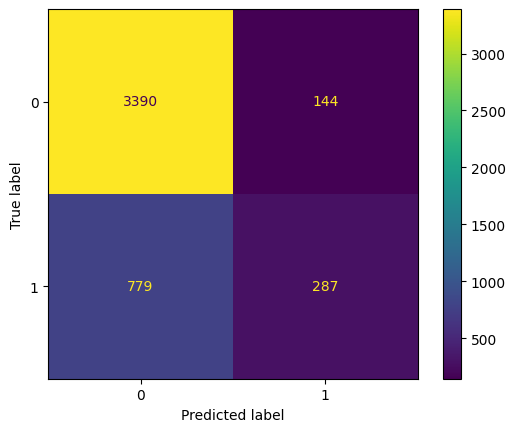

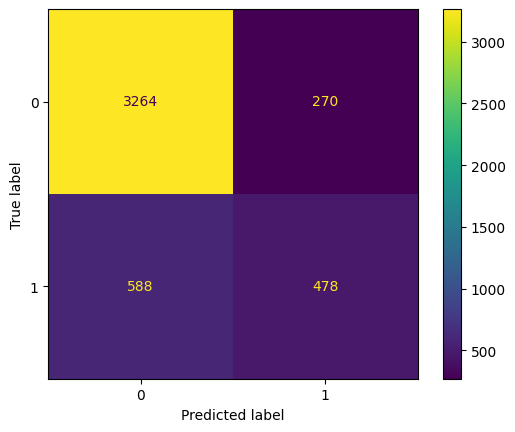

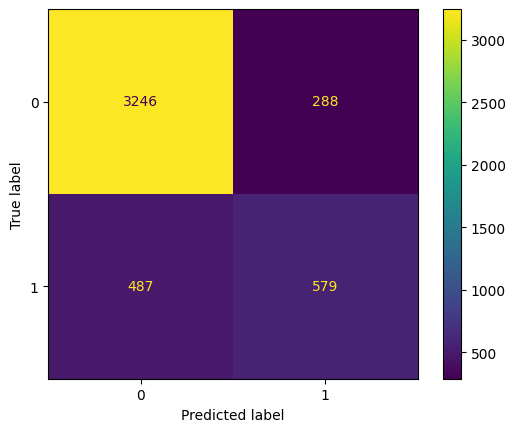

In [ ]:
#Confusion matrices for performance_results
for name, classifier in classifiers.items():
    cm = confusion_matrix(test_label,tpredictions[name])
    matrix = ConfusionMatrixDisplay(confusion_matrix=cm)
    matrix.plot()

Taking into account both the bar plots of the results DataFrame and the confusion matrices, we conclude that the optimal classifier appears to be the Perceptron (MLP). Along with Random Forest, the MLP achieved quite a good F1-score (close to 0.75); however, through the confusion matrix, the choice of the MLP becomes clear. The latter seems to have captured the non-linear relationships in the data better, as it managed to predict 607 TPs (28 more than the RF) while at the same time making 28 fewer critical errors than the RF (459 compared to 487). Despite the errors, the training appears to have succeeded, and the model returns fairly good results with quite accurate predictions.